# Segmentation marketing de clients par clustering (K-Means)

**Identifier des profils de clients à partir de leurs dépenses et de leurs habitudes d'achat, puis en tirer des actions marketing ciblées.**

Projet de data science de bout en bout : exploration et nettoyage des données, réduction de dimension (ACP, t-SNE), clustering K-Means, interprétation métier et recommandations.

---

## Objectif
Une entreprise de produits de consommation souhaite mieux connaître sa clientèle pour adapter ses offres. L'enjeu est de **regrouper les clients en segments homogènes** et de proposer, pour chacun, une stratégie marketing adaptée (produits, canal de communication, priorité).

## Données
- **Source :** jeu de données Kaggle « Customer Personality Analysis » (fichier `marketing_campaign.csv`, colonnes séparées par des tabulations).
- **Contenu :** 2 240 clients décrits par leur profil (année de naissance, revenu, enfants), leurs dépenses sur 6 catégories de produits, leurs achats par canal (web, catalogue, magasin), leurs visites web et leurs réponses à 6 campagnes marketing.
- **Après nettoyage :** 2 046 clients (valeurs manquantes imputées, 182 doublons et les valeurs aberrantes retirés).

## Démarche
1. **Exploration et nettoyage** : valeurs manquantes, valeurs aberrantes (règle de l'IQR), doublons, corrélations.
2. **Création de variables** : dépenses totales, achats totaux, nombre d'enfants, ancienneté, panier moyen.
3. **Réduction de dimension (ACP)** : 4 composantes suffisent pour dépasser 90 % de la variance ; PC1 = valeur et intensité d'achat, PC2 = ancienneté.
4. **Clustering K-Means** : choix de k par la méthode du coude et le score de silhouette, avec un test avant/après retrait d'un client aberrant qui faussait les résultats.
5. **Visualisation** : projection PCA avec zones de chevauchement, comparaison avec t-SNE.
6. **Interprétation marketing** : profils, noms des segments, recommandations.

Les réponses aux campagnes ne servent **pas** à construire les clusters : elles sont utilisées après coup pour vérifier la cohérence des segments.

## Résultats principaux
Trois segments de valeur très différente :

| Segment | Part des clients | Part des dépenses | Dépense moyenne | Réponse à la dernière campagne |
|---|---|---|---|---|
| **Gros acheteurs aisés** | 22 % | **56 %** | 1 503 | **31 %** |
| **Familles actives et sensibles aux promotions** | 30 % | 36 % | 732 | 13 % |
| **Petits budgets familiaux** | 48 % | 8 % | 104 | 9 % |

- Un petit nombre de clients concentre l'essentiel des dépenses : **22 % des clients génèrent 56 % des dépenses**.
- Priorités proposées : **fidéliser** les gros acheteurs (offres premium, catalogue, événements), **faire monter en valeur** les familles actives (offres groupées, fidélité, e-mail), **maintenir à moindre coût** les petits budgets.

## Limites
- La structure des données est **modérée** (silhouette ≈ 0,30) : les segments se chevauchent, surtout le segment intermédiaire.
- Les besoins et les stratégies sont des **hypothèses** déduites du comportement d'achat. Elles doivent être validées par des tests (A/B, enquêtes).
- Le potentiel est mesuré en **dépenses**, pas en marge : le jeu de données ne contient pas de coûts.

## Outils
Python · pandas · NumPy · scikit-learn (StandardScaler, PCA, KMeans, t-SNE) · SciPy · Matplotlib · Seaborn

## Exécuter le notebook
- **Google Colab :** exécutez les cellules dans l'ordre ; les données sont lues directement depuis le dépôt GitHub, sans téléversement.
- **En local :** clonez le dépôt (le fichier `marketing_campaign.csv` est inclus) et installez les bibliothèques ci-dessus (`pip install -r requirements.txt`).


## Contexte
Projet réalisé dans le contexte de l'équipe Data Marketing d'une entreprise de produits de consommation. L'objectif est d'identifier des segments de clients à partir de leurs caractéristiques socio-démographiques, de leurs dépenses et de leurs habitudes d'achat, puis de proposer des actions marketing adaptées.

**Précaution :** `AcceptedCmp1` à `AcceptedCmp5` et `Response` ne sont pas utilisées pour construire les clusters. Elles servent à analyser les segments après la segmentation.


# Description des variables — Segmentation marketing

Dataset : `marketing_campaign.csv` (séparateur tabulation) : 29 colonnes, une ligne par client.

## 1. Variables du dataset

### Identité et profil socio-démographique

| Variable | Type | Description |
|---|---|---|
| `ID` | int | Identifiant unique du client. Sans valeur analytique, à retirer avant le clustering. |
| `Year_Birth` | int | Année de naissance du client. Sert à calculer l'âge. |
| `Education` | catégorielle | Niveau d'études (ex. Graduation, PhD, Master, Basic, 2n Cycle). |
| `Marital_Status` | catégorielle | Situation familiale (Single, Married, Together, Divorced, Widow, plus quelques modalités atypiques : Alone, Absurd, YOLO). |
| `Income` | float | Revenu annuel du foyer. Contient des valeurs manquantes et des valeurs aberrantes. |
| `Kidhome` | int | Nombre d'enfants en bas âge dans le foyer. |
| `Teenhome` | int | Nombre d'adolescents dans le foyer. |
| `Dt_Customer` | catégorielle (date) | Date d'inscription du client dans l'entreprise (format `jj-mm-aaaa`). À convertir en date pour calculer l'ancienneté. |

### Comportement d'achat

| Variable | Type | Description |
|---|---|---|
| `Recency` | int | Nombre de jours depuis le dernier achat du client. |
| `NumDealsPurchases` | int | Nombre d'achats faits avec une remise ou une promotion. Mesure la sensibilité aux promotions. |
| `NumWebPurchases` | int | Nombre d'achats faits sur le site web de l'entreprise. |
| `NumCatalogPurchases` | int | Nombre d'achats faits par catalogue. |
| `NumStorePurchases` | int | Nombre d'achats faits directement en magasin. |
| `NumWebVisitsMonth` | int | Nombre de visites du site web sur le dernier mois. |

### Dépenses par catégorie de produits (sur les 2 dernières années)

| Variable | Type | Description |
|---|---|---|
| `MntWines` | int | Montant dépensé en vin. |
| `MntFruits` | int | Montant dépensé en fruits. |
| `MntMeatProducts` | int | Montant dépensé en viande. |
| `MntFishProducts` | int | Montant dépensé en poisson. |
| `MntSweetProducts` | int | Montant dépensé en confiseries et sucreries. |
| `MntGoldProds` | int | Montant dépensé en produits premium (« gold »). |

### Campagnes marketing (à ne pas utiliser pour construire les clusters)

| Variable | Type | Description |
|---|---|---|
| `AcceptedCmp1` | int (0/1) | 1 si le client a accepté l'offre de la 1re campagne, 0 sinon. |
| `AcceptedCmp2` | int (0/1) | 1 si le client a accepté l'offre de la 2e campagne, 0 sinon. |
| `AcceptedCmp3` | int (0/1) | 1 si le client a accepté l'offre de la 3e campagne, 0 sinon. |
| `AcceptedCmp4` | int (0/1) | 1 si le client a accepté l'offre de la 4e campagne, 0 sinon. |
| `AcceptedCmp5` | int (0/1) | 1 si le client a accepté l'offre de la 5e campagne, 0 sinon. |
| `Response` | int (0/1) | 1 si le client a accepté l'offre de la dernière campagne, 0 sinon. |

Ces variables servent uniquement à analyser les segments après le clustering.

### Autres

| Variable | Type | Description |
|---|---|---|
| `Complain` | int (0/1) | 1 si le client a déposé une réclamation lors des 2 dernières années, 0 sinon. |
| `Z_CostContact` | int | Variable technique, constante (3) pour tous les clients. Aucune information, à supprimer. |
| `Z_Revenue` | int | Variable technique, constante (11) pour tous les clients. Aucune information, à supprimer. |

# Partie 1 — Exploration

#### Exercice 1 : Découverte du dataset
1. Afficher les cinq premières observations et les dimensions.
2. Examiner les types de variables.
3. Identifier les variables numériques et catégorielles.
4. Rechercher les valeurs manquantes et les doublons.
5. Calculer les statistiques descriptives.
6. Repérer les variables pouvant contenir des valeurs aberrantes.

In [ ]:
# Importation des bibliothèques nécessaires
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.manifold import TSNE

# Chargement du Dataset
# Le fichier de données est publié dans le dépôt GitHub du projet.
# Si le dépôt a été cloné, on lit le fichier local ; sinon (Google Colab), on le lit directement sur GitHub.
import os
URL_DONNEES = "https://raw.githubusercontent.com/asaphmbere18-hub/segmentation-marketing-clients/main/marketing_campaign.xls"
FICHIER = "marketing_campaign.xls" if os.path.exists("marketing_campaign.xls") else URL_DONNEES

df = pd.read_csv(FICHIER, sep="\t")  # Le séparateur des colonnes est la tabulation
print(df.head())

In [ ]:
print("Type des variables")
print(df.dtypes)
print("\nIdentifions les variables numériques et catégorielles")
df_num = df.select_dtypes(include=[np.number])
df_cat = df.select_dtypes(exclude=[np.number])
print("\nVariables numériques :\n", df_num.columns.tolist())
print("\nVariables catégorielles :\n", df_cat.columns.tolist())
print("\nValeurs manquantes")
print(df.isnull().sum())

# Recherche des doublons : ID est unique, donc on cherche les clients au profil strictement identique (hors ID)
print("\nDoublons (toutes colonnes) :", df.duplicated().sum())
print("Doublons hors ID (profils identiques) :", df.drop(columns="ID").duplicated().sum())
print("Statistiques descriptives")
print(df.describe())
print("\nVariables pouvant contenir des valeurs aberrantes")

# 1. On crée une liste pour stocker les résultats
donnees_analyse = []

for col in df_num.columns:
    q_01 = df_num[col].quantile(0.01)
    q_99 = df_num[col].quantile(0.99)
    Q1, Q3 = df_num[col].quantile(0.25), df_num[col].quantile(0.75)
    IQR = Q3 - Q1
    min_val = df_num[col].min()
    max_val = df_num[col].max()

    # Vérification des alertes : valeur en dehors de [Q1 - 1,5 x IQR ; Q3 + 1,5 x IQR]
    alerte = "Oui" if (min_val < Q1 - 1.5 * IQR or max_val > Q3 + 1.5 * IQR) else "Non"

    # On ajoute les métriques dans notre liste
    donnees_analyse.append({
        "Colonne": col,
        "Min": min_val,
        "Max": max_val,
        "Quantile 1%": q_01,
        "Quantile 99%": q_99,
        "Alerte Valeurs Aberrantes": alerte
    })

# 2. On transforme la liste en DataFrame
df_analyse = pd.DataFrame(donnees_analyse)

# 3. On affiche le résultat
print(df_analyse)

#### Exercice 2 : Analyse exploratoire et visualisation
1. Représenter la distribution de `Income`.
2. Comparer les dépenses des six catégories de produits.
3. Étudier la distribution de l'âge.
4. Comparer les achats selon les canaux web, catalogue et magasin.
5. Construire une matrice de corrélation des variables numériques.
6. Commenter les relations entre revenus, dépenses, visites web et achats.

In [ ]:
# Visualisation des distributions des variables Income
# Configuration globale du style pour des graphiques professionnels
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 14})
plt.figure(figsize=(10, 5))

# Histogramme épuré avec une couleur moderne (ici bleu nuit/indigo)
sns.histplot(data=df, x='Income', bins=30, kde=True, color='#2b5c8f', alpha=0.85)

# Ajout d'une ligne verticale pour la médiane (plus robuste que la moyenne si outliers)
median_income = df['Income'].median()
plt.axvline(median_income, color='#e74c3c', linestyle='--', linewidth=2,
            label=f'Médiane : {median_income:,.0f}')

plt.title("Distribution de la variable Income (Revenu Annuel)", pad=15, weight='bold')
plt.xlabel("Revenu Annuel")
plt.ylabel("Nombre de Clients")
plt.legend()
plt.tight_layout()
plt.show()

# Visualisation des distributions des dépenses par catégorie de produits
# Création de la liste des colonnes représentant les dépenses par catégorie de produits
depenses_cols = ['MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds']

plt.figure(figsize=(12, 6))

# On passe les données en format "long" pour que Seaborn applique son potentiel optimal
df_long = df[depenses_cols].melt(var_name='Catégorie', value_name='Montant')

# Remplacement des noms de colonnes techniques par des labels propres
labels_propres = {
    'MntWines': 'Vin', 'MntFruits': 'Fruits', 'MntMeatProducts': 'Viande',
    'MntFishProducts': 'Poisson', 'MntSweetProducts': 'Sucreries', 'MntGoldProds': 'Premium'
}
df_long['Catégorie'] = df_long['Catégorie'].map(labels_propres)

# Création du boxplot avec une palette de couleurs harmonieuse
sns.boxplot(data=df_long, x='Catégorie', y='Montant', palette='Set2', hue='Catégorie', legend=False)
plt.title("Comparaison de la distribution des dépenses par catégorie de produits", pad=15, weight='bold')
plt.xlabel("Catégories de Produits")
plt.ylabel("Montant Dépensé")
plt.tight_layout()
plt.show()

# Distribution de l'âge
# Âge à la date de collecte des données : année de référence = année de la dernière inscription client (2014)
annee_reference = pd.to_datetime(df['Dt_Customer'], format='%d-%m-%Y').dt.year.max()
df['Age'] = annee_reference - df['Year_Birth']

plt.figure(figsize=(10, 5))
sns.histplot(data=df, x='Age', bins=30, kde=True, color='#2b5c8f', alpha=0.85)
median_age = df['Age'].median()
plt.axvline(median_age, color='#e74c3c', linestyle='--', linewidth=2, label=f'Médiane : {median_age:,.0f}')
plt.title("Distribution de la variable Age", pad=15, weight='bold')
plt.xlabel("Age")
plt.ylabel("Nombre de Clients")
plt.legend()
plt.tight_layout()
plt.show()

# Comparaisons des achats selon les canaux web, catalogue et magasin
channels_cols = ['NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases']

plt.figure(figsize=(12, 6))
df_long_channels = df[channels_cols].melt(var_name='Canal', value_name='Nombre d\'Achats')
labels_channels = {
    'NumWebPurchases': 'Web', 'NumCatalogPurchases': 'Catalogue', 'NumStorePurchases': 'Magasin'
}
df_long_channels['Canal'] = df_long_channels['Canal'].map(labels_channels)
sns.boxplot(data=df_long_channels, x='Canal', y='Nombre d\'Achats', palette='Set2', hue='Canal', legend=False)
plt.title("Comparaison des achats selon les canaux", pad=15, weight='bold')
plt.xlabel("Canaux")
plt.ylabel("Nombre d'Achats")
plt.tight_layout()
plt.show()

# Matrice de corrélation des variables numériques
plt.figure(figsize=(12, 8))
corr_matrix = df_num.select_dtypes(include=['float64', 'int64']).corr()
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', cbar=True)
plt.title("Matrice de corrélation des variables numériques", pad=15, weight='bold')
plt.tight_layout()
plt.show()

# Variables à fortes corrélations (une seule occurrence par paire)
corr_abs = corr_matrix.abs()
triangle_sup = np.triu(np.ones(corr_abs.shape, dtype=bool), k=1)   # k=1 exclut aussi la diagonale (corrélation avec soi-même)
strong_corr = corr_abs.where(triangle_sup).stack().sort_values(ascending=False)
strong_corr = strong_corr[strong_corr > 0.7]    # Seuil de corrélation forte
print("Variables à fortes corrélations :")
print(strong_corr)



In [ ]:
# Question 6 : relations entre revenus, dépenses, visites web et achats
# Base d'analyse : sans les doublons (profils identiques hors ID) et sans le revenu aberrant
df_q6 = df.drop(columns="ID").drop_duplicates()
df_q6 = df_q6[df_q6["Income"] < 600000]

comment = df_q6[["Income", "NumWebVisitsMonth"]].copy()
comment["Dépenses"] = df_q6[["MntWines", "MntFruits", "MntMeatProducts",
                             "MntFishProducts", "MntSweetProducts", "MntGoldProds"]].sum(axis=1)
# Achats = web + catalogue + magasin (les achats avec promotion sont déjà inclus dans ces canaux)
comment["Achats"] = df_q6[["NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases"]].sum(axis=1)

plt.figure(figsize=(6, 5))
sns.heatmap(comment.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Revenus, dépenses, visites web et achats")
plt.show()


# Commentaires
Analyse réalisée sur 2 033 clients : sans les doublons et sans le revenu aberrant (666 666).

* Revenus et dépenses (0.79) : la corrélation est positive et forte. Plus le revenu du foyer est élevé, plus les clients dépensent.
* Revenus et achats (0.73) : la corrélation est positive et forte. Un revenu élevé va avec plus d'achats.
* Dépenses et achats (0.82) : c'est la corrélation la plus forte. Ceux qui achètent souvent dépensent davantage.
* Visites web et revenus (-0.65) : la corrélation est négative et assez forte. Les clients qui visitent beaucoup le site ont des revenus plus faibles.
* Visites web et dépenses (-0.49) : la corrélation est négative et modérée. Beaucoup de visites ne se traduisent donc pas en dépenses élevées.
* Visites web et achats (-0.42) : la corrélation est négative et modérée. Les visites ne se convertissent pas bien en achats.

**Une corrélation ne prouve pas une causalité. Les clients plus modestes semblent surtout comparer sur le site avant d'acheter peu**


# Partie 2 — Nettoyage et feature engineering

#### Exercice 3 : Nettoyage
1. Identifier les valeurs manquantes de `Income`.
2. Proposer une stratégie de traitement.
3. Examiner les valeurs aberrantes de `Income` et `Year_Birth`.
4. Étudier les modalités de `Marital_Status` et `Education`.
5. Retirer les doublons et les variables non pertinentes pour le clustering (`ID`, variables techniques).
6. Exclure les réponses aux campagnes du clustering initial.

In [ ]:
# Identification des valeurs manquantes de Income
print("Valeurs manquantes de Income")
print(df[df["Income"].isna()])

# Stratégie pour gérer les valeurs manquantes de Income
# Remplacement des valeurs manquantes par la médiane
df["Income"] = df["Income"].fillna(df["Income"].median())
print("\nAprès remplacement des valeurs manquantes de Income")
print(df[df["Income"].isna()])

# Examinons les valeurs aberrantes de Income et Year_Birth
print("Valeurs aberrantes de Income")
print(df[df["Income"] > 600000])
print("\nValeurs aberrantes de Year_Birth")
print(df[df["Year_Birth"] < 1900])

# Boxplot pour visualiser les valeurs aberrantes
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
sns.boxplot(y=df["Income"])
plt.title("Boxplot de Income")
plt.subplot(1, 2, 2)
sns.boxplot(y=df["Year_Birth"])
plt.title("Boxplot de Year_Birth")
plt.show()

In [ ]:
# Revenus les plus élevés (repérage des valeurs aberrantes)
df['Income'].sort_values(ascending=False).head(10)


In [ ]:
# Étudions les modalités de Marital_Status et Education
# Remarque : Marital_Status contient quelques modalités atypiques (Alone, Absurd, YOLO) en très petit nombre.
# Ces deux variables catégorielles ne servent pas au clustering : on ne les regroupe pas.
print("Modalités de Marital_Status")
print(df["Marital_Status"].value_counts())
print("\nModalités de Education")
print(df["Education"].value_counts())

# Visualisation des modalités de Marital_Status et Education
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
sns.countplot(x="Marital_Status", data=df)
for p in plt.gca().patches:
    plt.gca().annotate(f'{p.get_height()}', (p.get_x() + p.get_width() / 2., p.get_height()),
                       ha='center', va='center', xytext=(0, 5), textcoords='offset points')
plt.xticks(rotation=45)
plt.title("Distribution de Marital_Status")
plt.subplot(1, 2, 2)
sns.countplot(x="Education", data=df)
for p in plt.gca().patches:
    plt.gca().annotate(f'{p.get_height()}', (p.get_x() + p.get_width() / 2., p.get_height()),
                       ha='center', va='center', xytext=(0, 5), textcoords='offset points')
plt.title("Distribution de Education")
plt.xticks(rotation=45)
plt.show()

In [ ]:
# Retirons les variables non pertinentes pour le clustering (ID, variables techniques)
df = df.drop(columns=["ID", "Z_Revenue", "Z_CostContact"])
print("Colonnes après suppression des variables non pertinentes :")
print(df.columns)

# Retirons les doublons : clients au profil strictement identique (une fois ID retiré)
print("\nNombre de lignes avant suppression des doublons :", len(df))
print("Doublons :", df.duplicated().sum())
df = df.drop_duplicates()
print("Nombre de lignes après suppression des doublons :", len(df))

# Exclusions des réponses aux campagnes du clustering initial
df = df.drop(columns=["AcceptedCmp1", "AcceptedCmp2", "AcceptedCmp3", "AcceptedCmp4", "AcceptedCmp5", "Response"])
print("\nColonnes après exclusion des réponses aux campagnes :")
print(df.columns)


#### Exercice 4 : Création de nouvelles variables
Créer :
- `Age` : année de référence moins `Year_Birth`.
- `Total_Spending` : somme des dépenses dans les six catégories.
- `Total_Purchases` : somme des achats web, catalogue et magasin.
- `Total_Children` : `Kidhome` + `Teenhome`.
- `Customer_Tenure` : ancienneté en jours depuis `Dt_Customer`.
- `Average_Spending` : dépenses totales divisées par le nombre total d'achats.

Expliquer l'intérêt et les limites de ces nouvelles variables.

In [ ]:
df["Total_Spending"]  = df[["MntWines","MntFruits","MntMeatProducts",
                                       "MntFishProducts","MntSweetProducts","MntGoldProds"]].sum(axis=1)
df["Total_Purchases"] = df[["NumWebPurchases","NumCatalogPurchases","NumStorePurchases"]].sum(axis=1)
df["Total_Children"]  = df["Kidhome"] + df["Teenhome"]

dates = pd.to_datetime(df["Dt_Customer"], format="%d-%m-%Y")
df["Customer_Tenure"] = (dates.max() - dates).dt.days

# Évite la division par zéro : 0 si aucun achat
df["Average_Spending"] = np.where(df["Total_Purchases"] == 0, 0,
                                  df["Total_Spending"] / df["Total_Purchases"]).round(2)
print(df.head())


### Intérêt et limites des nouvelles variables

| Variable | Intérêt | Limites |
|---|---|---|
| `Age` | Résume `Year_Birth` en une valeur parlante pour le marketing (jeunes, seniors…) et comparable entre clients. | Dépend de l'année de référence choisie : on retient 2014, année de la dernière inscription du fichier, afin que l'âge corresponde à la période de collecte des données (et non à aujourd'hui). Les années de naissance aberrantes (1893, 1899) donnent des âges de 121 et 115 ans et sont des valeurs aberrantes, éliminées lors du nettoyage (méthode de l'IQR). |
| `Total_Spending` | Donne une vue globale de la valeur du client à la place de six colonnes très corrélées. Réduit la redondance et le nombre de dimensions. | Masque la composition des dépenses : un client qui achète surtout du vin et un autre qui répartit ses achats peuvent avoir le même total. Très sensible aux gros acheteurs (valeurs extrêmes). |
| `Total_Purchases` | Mesure la fréquence d'achat tous canaux confondus, indépendamment du montant. | Ne distingue pas les canaux (web, catalogue, magasin). Les achats avec promotion (`NumDealsPurchases`) sont déjà inclus dans les canaux, il ne faut donc pas les ajouter. Un client peut avoir peu d'achats mais des paniers élevés. |
| `Total_Children` | Mesure simplement la charge familiale, qui influence les besoins et le budget du foyer. | Regroupe jeunes enfants et adolescents, alors que leurs besoins de consommation diffèrent. La valeur 0 ne dit pas si le foyer a un autre profil familial. |
| `Customer_Tenure` | Mesure l'ancienneté et la fidélité du client, utile pour distinguer anciens et nouveaux clients. | Dépend de la date de référence (ici la dernière inscription du fichier). Les inscriptions ne couvrent que deux ans (2012-2014), donc la variance est limitée. Ne dit rien sur l'activité réelle du client (voir `Recency`). |
| `Average_Spending` | Représente le panier moyen : distingue les gros paniers peu fréquents des petits paniers fréquents. | Non définie sans achat (`Total_Purchases` = 0), d'où une valeur imputée à 0 pour 4 clients. Fortement asymétrique, avec un maximum d'environ 1 679 pour une médiane d'environ 30. Calculée à partir d'autres variables, elle est corrélée à `Total_Spending` et `Total_Purchases`. |

**Limites communes :**
- Ces variables sont **dérivées** d'autres colonnes. Les garder avec leurs sources dans le clustering ou la PCA ajoute de la redondance et donne trop de poids à la même information. Il faut choisir l'un ou l'autre.
- Elles dépendent de **choix méthodologiques** : date de référence, traitement des valeurs nulles, exclusion des achats avec promotion.
- Les **valeurs extrêmes** des sources (par exemple `Income` à 666 666) se propagent aux variables calculées. Il faut les traiter avant la standardisation.


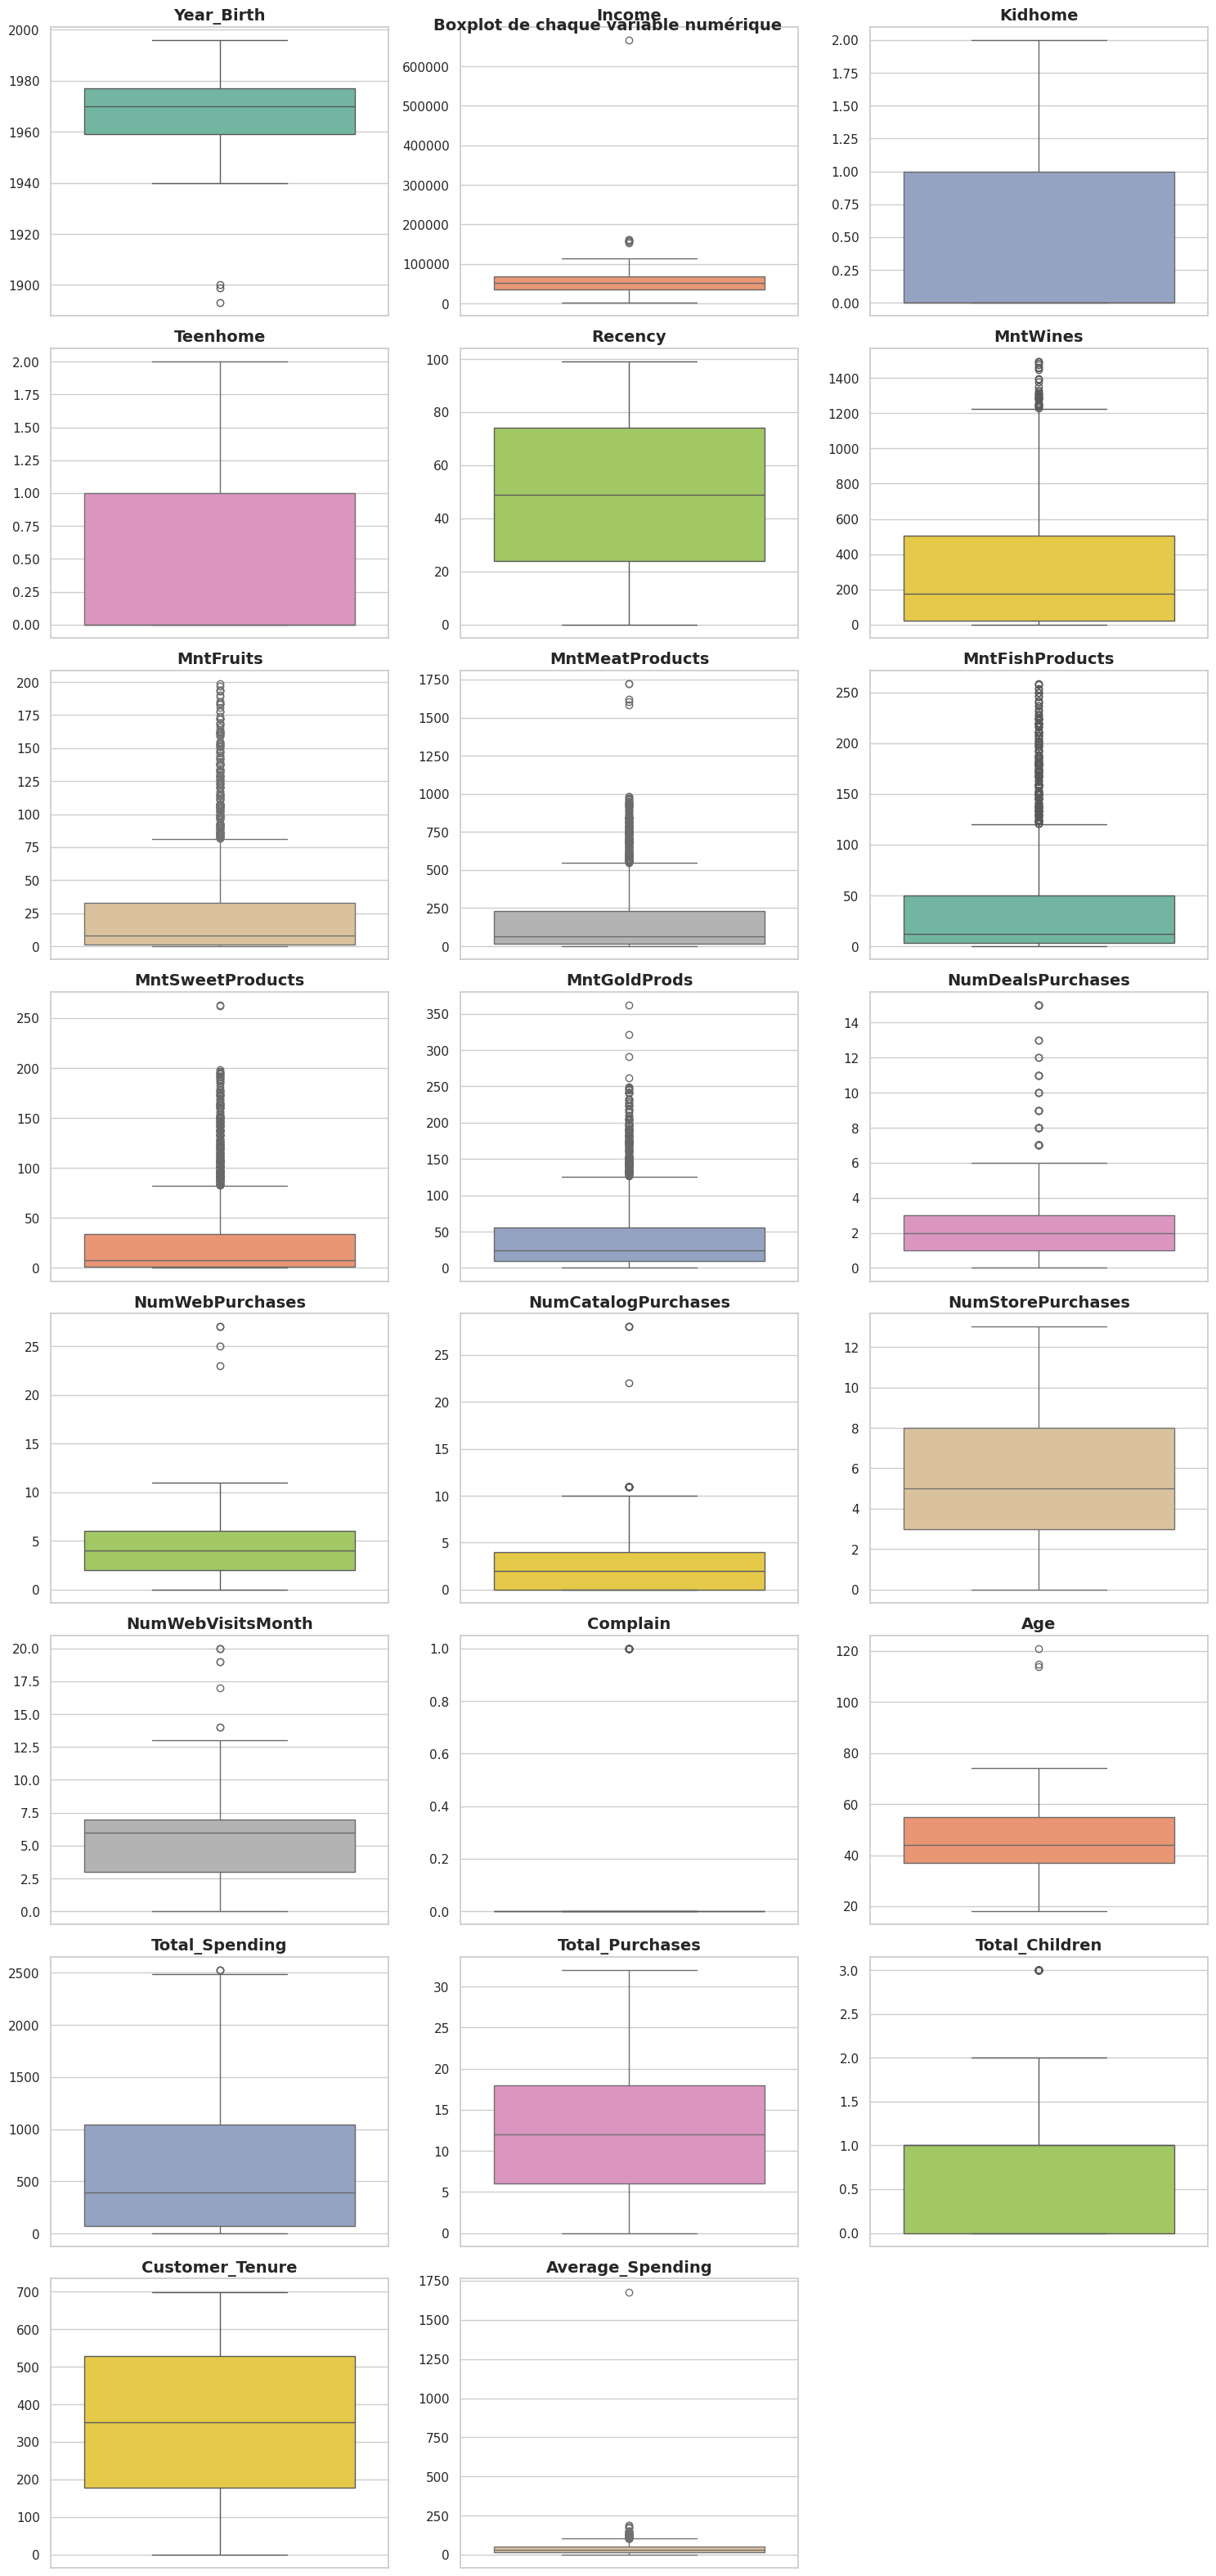

In [14]:
# Boxplot de chaque variable numérique (une échelle propre à chaque variable)
df_num = df.select_dtypes(include=["float64", "int64"])
n_cols = 3
n_rows = int(np.ceil(len(df_num.columns) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4 * n_rows))
axes = axes.flatten()
palette = sns.color_palette("Set2", len(df_num.columns))

for ax, col, color in zip(axes, df_num.columns, palette):
    sns.boxplot(y=df_num[col], ax=ax, color=color)
    ax.set_title(col, weight="bold")
    ax.set_ylabel("")

# Supprime les cases vides de la grille
for ax in axes[len(df_num.columns):]:
    ax.set_visible(False)

fig.suptitle("Boxplot de chaque variable numérique", fontsize=14, weight="bold")
plt.tight_layout()
plt.show()


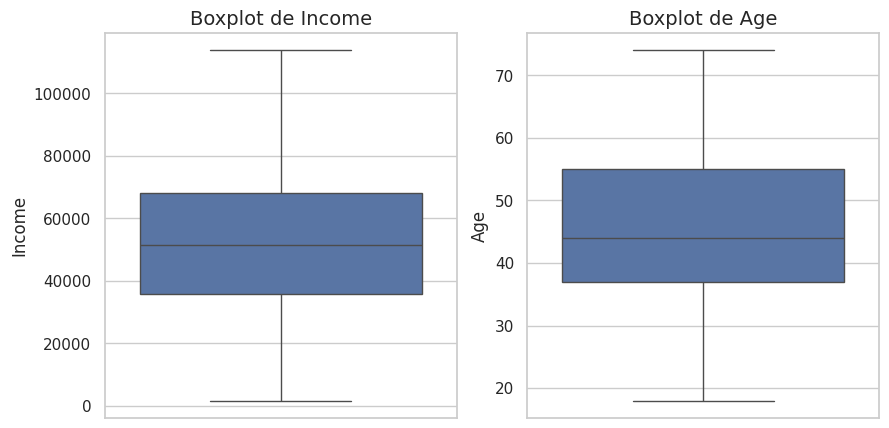

In [15]:
# Suppression des valeurs aberrantes des variables Age et Income
Q1_age = df['Age'].quantile(0.25)
Q3_age = df['Age'].quantile(0.75)
IQR_age = Q3_age - Q1_age
Q1_income = df['Income'].quantile(0.25)
Q3_income = df['Income'].quantile(0.75)
IQR_income = Q3_income - Q1_income

df = df[(df['Age'] >= Q1_age - 1.5 * IQR_age) & (df['Age'] <= Q3_age + 1.5 * IQR_age)]
df = df[(df['Income'] >= Q1_income - 1.5 * IQR_income) & (df['Income'] <= Q3_income + 1.5 * IQR_income)]

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
sns.boxplot(y=df["Income"])
plt.title("Boxplot de Income")
plt.subplot(1, 2, 2)
sns.boxplot(y=df["Age"])
plt.title("Boxplot de Age")
plt.show()

# Partie 3 — Réduction de dimension avec PCA

#### Exercice 5 : Application de PCA
1. Sélectionner les variables numériques pertinentes.
2. Standardiser les variables.
3. Entraîner une PCA sans fixer initialement le nombre de composantes.
4. Déterminer le nombre de composantes nécessaire pour conserver 90 % de la variance.

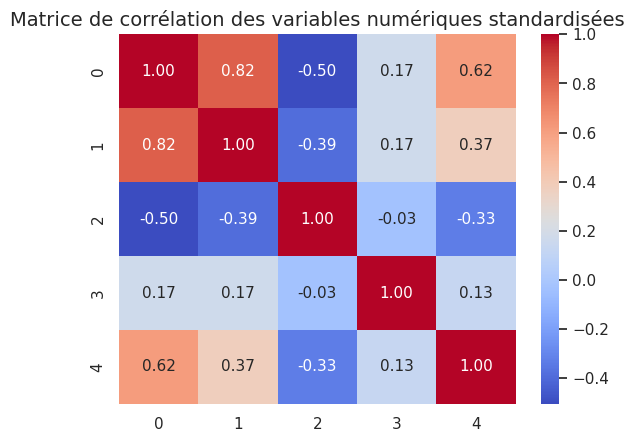

Nombre de composantes pour conserver 90% de la variance : 4


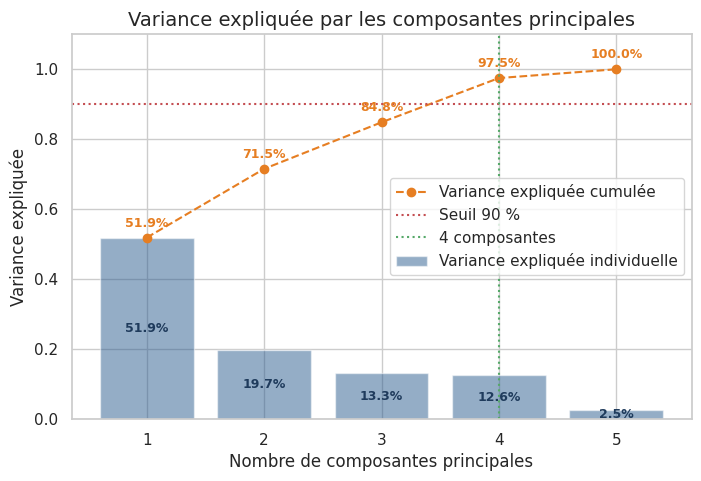

In [16]:
# Sélection des variables numériques pertinentes
numeric_features = ["Total_Spending", "Total_Purchases", "Total_Children", "Customer_Tenure", "Average_Spending"]
df_clustering_numeric = df[numeric_features]

# Standardisation des variables numériques
scaler = StandardScaler()
df_clustering_numeric_scaled = scaler.fit_transform(df_clustering_numeric)

# Matrice de covariance des variables standardisées (équivalente à la matrice de corrélation)
cov_matrix = np.cov(df_clustering_numeric_scaled, rowvar=False)
sns.heatmap(cov_matrix, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Matrice de corrélation des variables numériques standardisées")
plt.show()

# Entraînement d'une PCA sans fixer initialement le nombre de composantes
pca = PCA()
df_clustering_pca = pca.fit_transform(df_clustering_numeric_scaled)

# Détermination du nombre de composantes nécessaires pour conserver 90% de la variance
explained_variance_ratio_cumsum = np.cumsum(pca.explained_variance_ratio_)
n_components_90 = np.argmax(explained_variance_ratio_cumsum >= 0.9) + 1
print("Nombre de composantes pour conserver 90% de la variance :", n_components_90)

# Réduction de la dimensionnalité en utilisant le nombre de composantes déterminé
pca = PCA(n_components=n_components_90)
df_clustering_pca = pca.fit_transform(df_clustering_numeric_scaled)

# Visualisation de la variance expliquée par chaque composante principale
plt.figure(figsize=(8, 5))
components = np.arange(1, len(explained_variance_ratio_cumsum) + 1)
individual_variance = np.diff(explained_variance_ratio_cumsum, prepend=0)

plt.bar(components, individual_variance, alpha=0.5, color='#2b5c8f', label='Variance expliquée individuelle')
plt.plot(components, explained_variance_ratio_cumsum, marker='o', linestyle='--', color='#e67e22', label='Variance expliquée cumulée')
plt.axhline(0.9, color='r', linestyle=':', label='Seuil 90 %')
plt.axvline(n_components_90, color='g', linestyle=':', label=f'{n_components_90} composantes')

# Affichage des valeurs sur les barres (variance individuelle)
for x, y in zip(components, individual_variance):
    plt.text(x, y / 2, f"{y:.1%}", ha='center', va='center', fontsize=9, color='#1f3b5c', weight='bold')

# Affichage des valeurs sur les points (variance cumulée)
for x, y in zip(components, explained_variance_ratio_cumsum):
    plt.annotate(f"{y:.1%}", (x, y), textcoords="offset points", xytext=(0, 8),
                 ha='center', fontsize=9, color='#e67e22', weight='bold')

plt.xticks(components)
plt.ylim(0, 1.1)
plt.legend(loc='center right')
plt.xlabel("Nombre de composantes principales")
plt.ylabel("Variance expliquée")
plt.title("Variance expliquée par les composantes principales")
plt.show()



**Variables retenues.** L'ACP porte sur les 5 variables construites à l'Exercice 4 (`Total_Spending`, `Total_Purchases`, `Total_Children`, `Customer_Tenure`, `Average_Spending`). Elles résument les 6 dépenses par catégorie et les 3 canaux d'achat dans un petit nombre de variables lisibles, et évitent de compter plusieurs fois la même information. `Income`, `Recency`, `NumWebVisitsMonth` et `NumDealsPurchases` ne sont pas retenues : elles servent à **décrire** les segments après coup.

**Graphique : variance expliquée par les composantes**

Les barres montrent la part de variance portée par chaque composante, la courbe orange la part cumulée.
- PC1 explique **52 %** de la variance, PC2 **19,7 %**, PC3 **13,3 %**, PC4 **12,6 %** et PC5 seulement **2,5 %**.
- Les deux premières composantes cumulent **71,5 %**. Une visualisation en 2D conserve donc l'essentiel de l'information, mais pas tout : environ 28 % est perdu.
- Avec 3 composantes, on atteint **85 %**, ce qui reste sous le seuil de 90 %.
- Le seuil de 90 % (ligne rouge) est franchi à **4 composantes** (97,5 %). C'est le nombre retenu pour la suite, avec une perte d'information de 2,5 % seulement.
- La cinquième composante n'apporte presque rien : les 5 variables initiales peuvent se résumer en 4 dimensions sans perte importante.
- Les composantes PC2 à PC4 ont des variances assez proches (13 à 20 %). Il n'y a donc pas de « coude » net après PC1, ce qui indique que l'information est répartie sur plusieurs dimensions.

#### Exercice 6 : Interprétation des composantes principales
1. Projeter les clients sur PC1 et PC2.
2. Identifier les variables les plus associées à PC1 et PC2.
3. Interpréter les deux premières composantes.

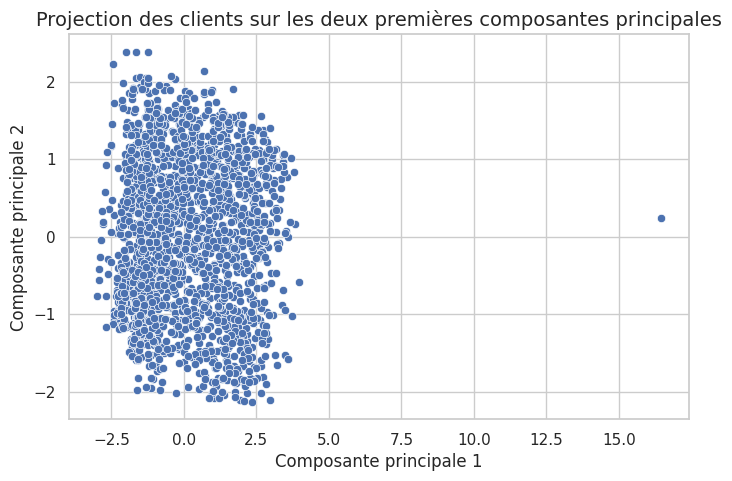

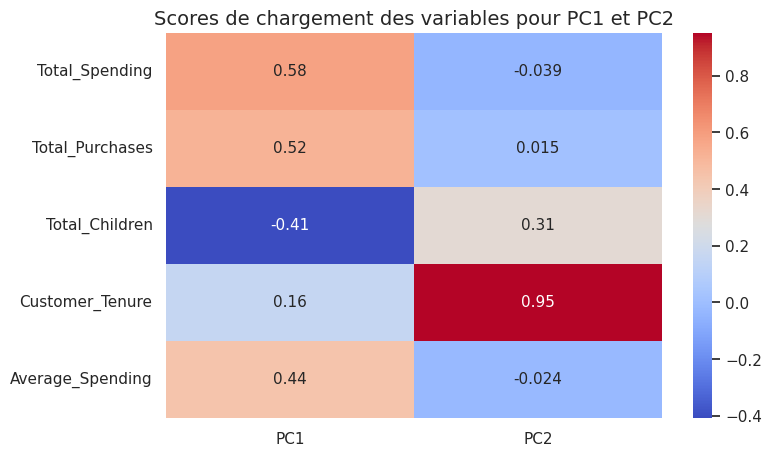

In [17]:
# --- Graphique 1 : projection des clients sur PC1 et PC2 ---
plt.figure(figsize=(8, 5))                    # Crée une figure de 8 x 5 pouces
sns.scatterplot(x=df_clustering_pca[:, 0],    # Axe X : coordonnées des clients sur PC1 (colonne 0)
                y=df_clustering_pca[:, 1])    # Axe Y : coordonnées des clients sur PC2 (colonne 1)
plt.xlabel("Composante principale 1")
plt.ylabel("Composante principale 2")
plt.title("Projection des clients sur les deux premières composantes principales")
plt.show()

# --- Graphique 2 : variables les plus associées à PC1 et PC2 ---
# Tableau des chargements : pca.components_ contient les poids de chaque variable
# dans chaque composante ; .T inverse le tableau pour avoir une ligne par variable
loading_scores = pd.DataFrame(
    pca.components_.T,                                          # Poids (variables en lignes)
    index=numeric_features,                                     # Noms des variables en lignes
    columns=[f"PC{i+1}" for i in range(pca.n_components_)])     # Noms PC1, PC2, ... en colonnes
loading_scores[["PC1", "PC2"]]                                  # Affiche seulement PC1 et PC2
plt.figure(figsize=(8, 5))                                      # Crée une figure de 8 x 5 pouces
sns.heatmap(loading_scores[["PC1", "PC2"]],                     # Carte de chaleur des chargements
            annot=True,                                         # Écrit la valeur dans chaque case
            cmap="coolwarm")                                    # Bleu = négatif, rouge = positif
plt.title("Scores de chargement des variables pour PC1 et PC2")
plt.show()


### Interprétation des graphiques

**Graphique 1 : projection des clients sur PC1 et PC2**

Chaque point est un client. Son abscisse est son score sur PC1 et son ordonnée son score sur PC2.
- La grande majorité des clients forme un nuage compact : PC1 va d'environ -3 à 4 et PC2 de -2,1 à 2,4. Aucun groupe n'est nettement séparé, ce qui laisse prévoir des segments qui se chevauchent.
- Un client est très isolé à droite, avec PC1 ≈ 16. C'est un **point aberrant** : un client avec un seul achat pour 1 679 de dépenses, donc un `Average_Spending` extrême. Il étire l'axe horizontal et comprime visuellement tous les autres clients.
- Le nuage est plus étalé verticalement qu'horizontalement par rapport à sa largeur utile, ce qui est cohérent avec le fait que PC2 reflète surtout l'ancienneté.

**Graphique 2 : scores de chargement (poids des variables)**

Plus une valeur est proche de 1 ou de -1, plus la variable contribue à la composante. Le rouge indique une contribution positive, le bleu une contribution négative.
- **PC1** : `Total_Spending` (0.58), `Total_Purchases` (0.52) et `Average_Spending` (0.44) ont des poids positifs. `Total_Children` a un poids négatif (-0.41). `Customer_Tenure` pèse peu (0.16).
- **PC2** : `Customer_Tenure` domine presque seule (0.95). `Total_Children` contribue un peu (0.31). Les trois autres variables sont proches de 0.

**Graphique 3 : variance expliquée par les composantes**

Les barres montrent la part de variance portée par chaque composante, la courbe orange la part cumulée.
- PC1 explique **52 %** de la variance, PC2 **19,7 %**, PC3 **13,3 %**, PC4 **12,6 %** et PC5 seulement **2,5 %**.
- Les deux premières composantes cumulent **71,5 %**. Une visualisation en 2D conserve donc l'essentiel de l'information, mais pas tout : environ 28 % est perdu.
- Avec 3 composantes, on atteint **85 %**, ce qui reste sous le seuil de 90 %.
- Le seuil de 90 % (ligne rouge) est franchi à **4 composantes** (97,5 %). C'est le nombre retenu pour la suite, avec une perte d'information de 2,5 % seulement.
- La cinquième composante n'apporte presque rien : les 5 variables initiales peuvent se résumer en 4 dimensions sans perte importante.
- Les composantes PC2 à PC4 ont des variances assez proches (13 à 20 %). Il n'y a donc pas de « coude » net après PC1, ce qui indique que l'information est répartie sur plusieurs dimensions.

### Interprétation des deux premières composantes

**PC1 : l'axe « valeur et intensité d'achat » (52 %)**
Les trois variables d'achat montent ensemble : un client qui a un score élevé sur PC1 dépense beaucoup (`Total_Spending`), achète souvent (`Total_Purchases`) et a un panier moyen élevé (`Average_Spending`). Le poids négatif de `Total_Children` signifie que les foyers avec plus d'enfants se retrouvent à gauche de l'axe : ils dépensent et achètent moins.
- **À droite (PC1 élevé)** : clients gros acheteurs, peu ou pas d'enfants.
- **À gauche (PC1 faible)** : clients qui achètent peu, souvent avec enfants.

**PC2 : l'axe « ancienneté » (19,7 %)**
PC2 est presque entièrement portée par `Customer_Tenure` (0.95). Elle est indépendante du comportement d'achat, puisque les chargements des variables d'achat sont proches de 0. Le poids de `Total_Children` (0.31) est faible.
- **En haut (PC2 élevé)** : clients inscrits depuis longtemps.
- **En bas (PC2 faible)** : clients récemment inscrits.

**Conclusion** : les deux premières composantes séparent deux dimensions indépendantes : ce que le client achète (PC1) et depuis quand il est client (PC2). Pour segmenter, c'est surtout PC1 qui distingue les profils. PC2 apporte une information d'ancienneté, qui peut être moins utile commercialement.


# Partie 4 — Clustering avec K-Means

#### Exercice 7 : Première application de K-Means
1. Utiliser les variables standardisées retenues.
2. Instancier K-Means avec 3 clusters.
3. Entraîner le modèle et récupérer les labels.
4. Ajouter les labels au DataFrame.
5. Afficher la taille et le profil moyen de chaque cluster.

Dimensions des données standardisées : (2047, 5)

Variables utilisées : ['Total_Spending', 'Total_Purchases', 'Total_Children', 'Customer_Tenure', 'Average_Spending']

Clusters ajoutés au DataFrame :
   Total_Spending  Total_Purchases  Total_Children  Customer_Tenure  \
0            1617               22               0              663   
1              27                4               2              113   
2             776               20               0              312   
3              53                6               1              139   
4             422               14               1              161   

   Average_Spending  cluster  
0             73.50        1  
1              6.75        0  
2             38.80        1  
3              8.83        0  
4             30.14        0  

Taille de chaque cluster :
         Clients  Part (%)
cluster                   
0           1195     58.38
1            851     41.57
2              1      0.05

Profil moyen de chaque 

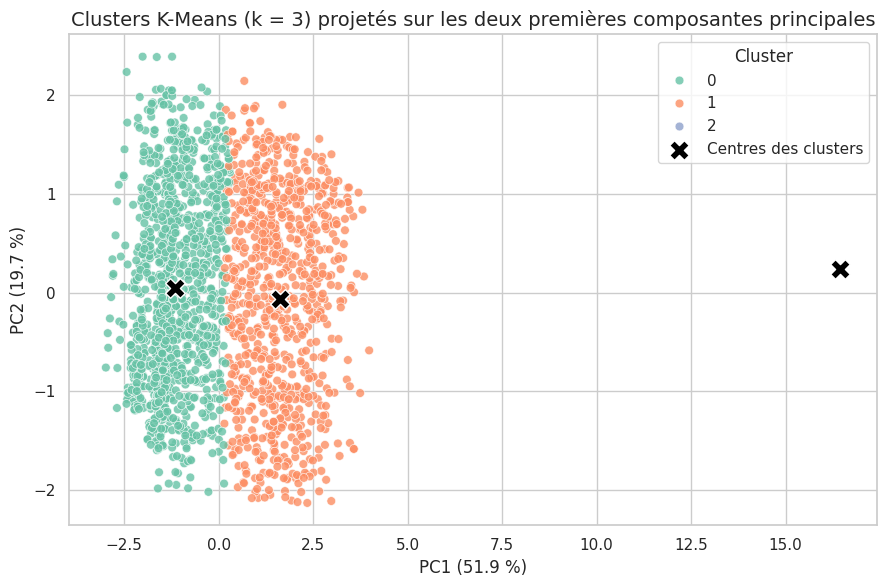

In [18]:
# Utilisation des variables standardisées retenues
X_selected_scaled = df_clustering_numeric_scaled
print("Dimensions des données standardisées :", X_selected_scaled.shape)
print("\nVariables utilisées :", numeric_features)

# Instanciation du modèle K-Means avec 3 clusters
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

# Entraînement du modèle K-Means
kmeans.fit(X_selected_scaled)

# Récupération des labels
labels = kmeans.labels_

# Ajout des labels de clusters au DataFrame
df['cluster'] = labels
print("\nClusters ajoutés au DataFrame :")
print(df[numeric_features + ['cluster']].head())

# Taille de chaque cluster (effectif et pourcentage)
taille = df['cluster'].value_counts().sort_index()
print("\nTaille de chaque cluster :")
print(pd.DataFrame({"Clients": taille, "Part (%)": (taille / len(df) * 100).round(2)}))

# Profil moyen de chaque cluster : variables du clustering + variables d'interprétation
profil_cols = numeric_features + ["Income", "Age", "NumWebVisitsMonth", "NumDealsPurchases"]
print("\nProfil moyen de chaque cluster :")
print(df.groupby('cluster')[profil_cols].mean().round(2))

# Visualisation des clusters
plt.figure(figsize=(9, 6))

# Projection des clients sur PC1 et PC2, colorés selon leur cluster
sns.scatterplot(x=df_clustering_pca[:, 0], y=df_clustering_pca[:, 1],
                hue=df['cluster'], palette="Set2", s=40, alpha=0.8)

# Projection des centres des clusters dans le même repère (ils sont dans l'espace standardisé)
centres_pca = pca.transform(kmeans.cluster_centers_)
plt.scatter(centres_pca[:, 0], centres_pca[:, 1], c="black", marker="X", s=200,
            edgecolor="white", label="Centres des clusters")

# Axes avec la part de variance expliquée par chaque composante
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0] * 100:.1f} %)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1] * 100:.1f} %)")
plt.title("Clusters K-Means (k = 3) projetés sur les deux premières composantes principales")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()


#### Exercice 8 : Recherche du nombre de clusters
1. Entraîner K-Means pour K allant de 2 à 10.
2. Récupérer l'inertie.
3. Tracer la courbe Elbow.
4. Calculer le Silhouette Score.
5. Choisir un K pertinent et entraîner le modèle final.

Pour k=2, inertie=6259.72
Pour k=3, inertie=5082.27
Pour k=4, inertie=4293.22
Pour k=5, inertie=3525.88
Pour k=6, inertie=3051.86
Pour k=7, inertie=2616.74
Pour k=8, inertie=2364.07
Pour k=9, inertie=2119.86
Pour k=10, inertie=1969.91


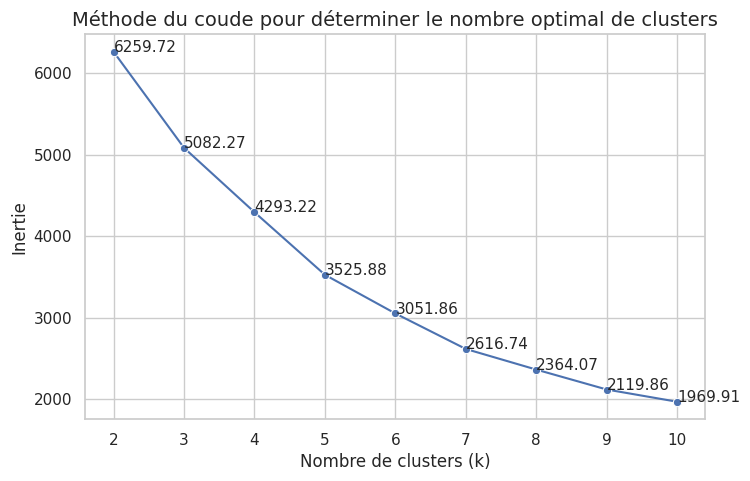

In [19]:
# Entraînons k-means pour k allant de 2 à 10
inertias = []
for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_selected_scaled)
    inertias.append(kmeans.inertia_)

# Récupération de l'inertie pour chaque k
for k, inertia in zip(range(2, 11), inertias):
    print(f"Pour k={k}, inertie={round(inertia, 2)}")
# Affichage du graphique de l'inertie en fonction de k
# Traçons la courbe de Elbow (méthode du coude)
plt.figure(figsize=(8, 5))
sns.lineplot(x=range(2, 11), y=inertias, marker='o')
for k, inertia in zip(range(2, 11), inertias):
    plt.text(k, inertia, str(round(inertia, 2)))
plt.xlabel('Nombre de clusters (k)')
plt.ylabel('Inertie')
plt.title('Méthode du coude pour déterminer le nombre optimal de clusters')
plt.show()

### Choix du nombre de clusters

#### 1. Méthode du coude (avant retrait du client aberrant)

L'inertie mesure la compacité des clusters : plus elle est basse, plus les clients d'un même cluster sont proches. Elle baisse toujours quand k augmente, on ne peut donc pas simplement prendre la valeur la plus basse. On cherche le « coude », c'est-à-dire le point à partir duquel ajouter un cluster ne fait plus gagner grand-chose.

| Passage | Gain d'inertie | En % |
|---|---|---|
| 2 → 3 | −1 177 | −18,8 % |
| 3 → 4 | −789 | −15,5 % |
| 4 → 5 | −767 | −17,9 % |
| 5 → 6 | −474 | −13,4 % |
| 6 → 7 | −435 | −14,3 % |
| 7 → 8 | −253 | −9,7 % |

**Interprétation :** l'inertie passe de 6 260 (k = 2) à 1 970 (k = 10) et la courbe descend de façon régulière, **sans coude net**. Un léger aplatissement apparaît vers k = 7 ou 8, mais il est discret. Ce critère ne permet donc pas de choisir k à lui seul. C'est fréquent sur des données de clients, où les groupes se chevauchent.


In [ ]:
# Calcul de la Silhouette Score
silhouette_scores = []
for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_selected_scaled)
    score = silhouette_score(X_selected_scaled, labels)
    silhouette_scores.append(score)
    print(f"Pour k={k}, silhouette score={round(score, 2)}")

# Affichage du graphique de la Silhouette Score en fonction de k
plt.figure(figsize=(8, 5))
sns.lineplot(x=range(2, 11), y=silhouette_scores, marker='o')
for k, score in zip(range(2, 11), silhouette_scores):
    plt.text(k, score, str(round(score, 2)))
plt.xlabel('Nombre de clusters (k)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score pour différents nombres de clusters')
plt.show()

#### 2. Score de silhouette (avant retrait du client aberrant)

Il mesure à quel point chaque client est proche de son cluster et éloigné des autres. Il va de −1 à 1 : plus il est élevé, mieux les clusters sont séparés.

| k | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 | 10 |
|---|---|---|---|---|---|---|---|---|---|
| Silhouette | 0,39 | **0,39** | 0,29 | 0,28 | 0,29 | 0,29 | 0,30 | 0,31 | 0,31 |

**Interprétation :**
- Les meilleurs scores sont obtenus pour **k = 2 et k = 3** (environ 0,39), quasiment à égalité.
- Il y a une **chute nette à k = 4** (0,29), puis un minimum à k = 5 (0,28).
- Le score remonte lentement ensuite, sans retrouver 0,39.
- Un score de 0,39 indique une structure **modérée** : les clusters existent mais se chevauchent.

À ce stade, **k = 3 semble le meilleur choix** (score maximal, avec k = 2). Mais ce résultat est-il fiable ? Il faut d'abord vérifier l'influence des valeurs extrêmes.


In [ ]:
from sklearn.metrics import silhouette_score

# Client aberrant : un seul achat pour 1 679 de dépenses
idx_aberrant = df["Average_Spending"].idxmax()
print(df.loc[idx_aberrant, numeric_features])

def evaluer_k(X, k_range=range(2, 11)):
    inertie, silhouette, petit_cluster = [], [], []
    for k in k_range:
        km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X)
        inertie.append(km.inertia_)
        silhouette.append(silhouette_score(X, km.labels_))
        petit_cluster.append(np.bincount(km.labels_).min())
    return pd.DataFrame({"k": list(k_range), "Inertie": inertie,
                         "Silhouette": silhouette, "Plus petit cluster": petit_cluster})

# Avant : tous les clients
X_avant = StandardScaler().fit_transform(df[numeric_features])
res_avant = evaluer_k(X_avant)

# Après : sans le client aberrant
df_propre = df.drop(index=idx_aberrant, columns="cluster")
X_apres = StandardScaler().fit_transform(df_propre[numeric_features])
res_apres = evaluer_k(X_apres)

print("AVANT :\n", res_avant.round(3))
print("\nAPRÈS :\n", res_apres.round(3))

# Comparaison graphique
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
couleurs = {"Avant": "tab:blue", "Après": "tab:orange"}
offsets = {"Avant": (0, 10), "Après": (0, -16)}

for res, label in [(res_avant, "Avant"), (res_apres, "Après")]:
    axes[0].plot(res["k"], res["Inertie"], marker="o", label=label, color=couleurs[label])
    axes[1].plot(res["k"], res["Silhouette"], marker="o", label=label, color=couleurs[label])
    for k, inertia, score in zip(res["k"], res["Inertie"], res["Silhouette"]):
        axes[0].annotate(f"{inertia:.0f}", (k, inertia), textcoords="offset points",
                         xytext=offsets[label], ha="center", fontsize=8, color=couleurs[label])
        axes[1].annotate(f"{score:.2f}", (k, score), textcoords="offset points",
                         xytext=offsets[label], ha="center", fontsize=8, color=couleurs[label])

axes[0].set_title("Méthode du coude : avant / après")
axes[0].set_xlabel("Nombre de clusters (k)"); axes[0].set_ylabel("Inertie")
axes[1].set_title("Silhouette : avant / après")
axes[1].set_xlabel("Nombre de clusters (k)"); axes[1].set_ylabel("Silhouette")
for ax in axes: ax.legend()
plt.tight_layout()
plt.show()

#### 3. Effet du client aberrant : avant / après nettoyage

L'analyse des variables a révélé un client atypique : il a effectué **un seul achat pour 1 679 de dépenses** (panier moyen de 1 679, alors que le client suivant est à 188). Comme K-Means repose sur des distances, un point aussi éloigné peut fausser les courbes ci-dessus.

Pour le vérifier, les deux critères ont été recalculés **avant** (2047 clients) et **après** (2046 clients) le retrait de ce client.

**Méthode du coude :**
- L'inertie « après » est nettement plus basse pour les petites valeurs de k (environ 5 575 contre 6 260 pour k = 2, et 4 614 contre 5 082 pour k = 3) : ce client éloigné pesait lourd dans le calcul.
- À partir de k = 7, les deux courbes se confondent : dès que K-Means lui consacre un cluster, son effet sur l'inertie disparaît.
- Dans les deux cas, la courbe reste régulière et **sans coude net**.

**Silhouette :**
- **k = 2** : le score monte à 0,40 après retrait (contre 0,39).
- **k = 3** : le score **chute de 0,39 à 0,30**. C'est le changement le plus important du graphique.
- **k = 4 et k = 5** : légère baisse, à environ 0,27.
- **k ≥ 6** : les deux courbes sont presque identiques (0,28 à 0,31).

**Explication :** avant retrait, K-Means isole ce client dans un cluster à lui seul pour k ≥ 3, ce qui fausse le calcul : un point très éloigné de tous les autres augmente artificiellement la silhouette. Le score de **0,39 à k = 3 était donc un artefact**, et non le signe d'une vraie séparation des clients. Il est conseillé de vérifier ce point en affichant la taille du plus petit cluster pour chaque k.


#### 4. Décision : choix de k

**Comparaison de k = 2 et k = 3 (après nettoyage) :**

| | k = 2 | k = 3 |
|---|---|---|
| Silhouette | **0,40** | 0,30 |
| Segments obtenus | Petits acheteurs et gros acheteurs | Petits acheteurs, **groupe intermédiaire** et gros acheteurs |
| Intérêt marketing | Faible : une seule distinction | Plus riche : trois niveaux de valeur client, donc trois actions possibles |

- **k = 2** : meilleur score de silhouette (0,40), mais ne sépare que gros et petits acheteurs. C'est trop pauvre pour proposer des stratégies différenciées.
- **k = 3** : silhouette plus faible (0,30), mais permet de distinguer un groupe intermédiaire en plus des petits et des gros acheteurs.
- Les deux ont une **structure modérée** : des scores de 0,30 à 0,40 indiquent des groupes qui se chevauchent, comme le montrait déjà la projection PCA.

**Choix retenu : k = 3**, à condition de le justifier par l'**intérêt marketing** et non par la silhouette. Si l'on ne suivait que le critère statistique, ce serait k = 2.

**Arguments pour k = 3 :**
- Le score (0,30) reste du même ordre que ceux de k = 4 à 10, sans dégradation importante.
- La baisse d'inertie reste forte jusqu'à k = 3 (environ −17 % par rapport à k = 2).
- La segmentation est directement exploitable : trois niveaux de valeur client permettent trois actions marketing distinctes.

**Limites :**
- La structure est modérée : les segments se chevauchent et certains clients sont proches d'une frontière entre deux groupes.
- Le choix de k = 3 repose autant sur l'interprétation marketing que sur la statistique : il n'est pas imposé par les données.
- Les résultats dépendent du traitement des valeurs aberrantes. Sans nettoyage préalable, un cluster serait consacré à un seul client.
- Les clusters doivent être décrits et nommés **après** ce nettoyage, car leur composition change.


In [ ]:
# Entraînement du k sur le modèle final
k_final = 3  # Choix du nombre de clusters basé sur l'analyse précédente

# Données propres après suppression du client aberrant
df_propre = df.drop(index=idx_aberrant, columns="cluster").copy()

# Standardisation des données après suppression du client aberrant
X_apres = StandardScaler().fit_transform(df_propre[numeric_features])

# Instanciation et entraînement du modèle final
kmeans_final = KMeans(n_clusters=k_final, random_state=42, n_init=10)
df_propre["Cluster"] = kmeans_final.fit_predict(X_apres)

# Labels finaux pour chaque client après suppression du client aberrant
labels_final = df_propre["Cluster"]

# PCA refaite après suppression du client aberrant
pca_propre= PCA(n_components=2)
X_pca = pca_propre.fit_transform(X_apres)

# Taille et profil moyen des clusters après suppression du client aberrant
print("Taille des clusters :")
print(df_propre["Cluster"].value_counts())
print("\nProfil moyen des clusters :")
print(df_propre.groupby("Cluster")[numeric_features].mean())

#### Exercice 9 : Visualisation des clusters avec PCA
1. Projeter les clients sur les deux premières composantes principales.
2. Colorer les points selon leur cluster K-Means.
3. Repérer les zones de chevauchement.
4. Commenter la qualité et les limites de cette visualisation.

In [ ]:
from scipy.stats import gaussian_kde
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

df_propre["PCA1"] = X_pca[:, 0]
df_propre["PCA2"] = X_pca[:, 1]

clusters = sorted(df_propre["Cluster"].unique())
couleurs = dict(zip(clusters, sns.color_palette("Set2", len(clusters))))

print(f"Variance expliquée par les deux premières composantes : {pca_propre.explained_variance_ratio_[:2].sum() * 100:.1f} %")
fig, ax = plt.subplots(figsize=(11, 7))

# 1) Zones de densité de chaque cluster (fond coloré + lignes de contour)
sns.kdeplot(x=df_propre["PCA1"], y=df_propre["PCA2"], hue=df_propre["Cluster"],
            palette=couleurs, fill=True, alpha=0.25, levels=5, legend=False, ax=ax)
sns.kdeplot(x=df_propre["PCA1"], y=df_propre["PCA2"], hue=df_propre["Cluster"],
            palette=couleurs, fill=False, levels=5, linewidths=1, legend=False, ax=ax)

# 2) Zones de chevauchement : là où au moins 2 clusters ont une densité significative
xx, yy = np.meshgrid(np.linspace(*ax.get_xlim(), 200), np.linspace(*ax.get_ylim(), 200))
grille = np.vstack([xx.ravel(), yy.ravel()])
presence = np.zeros(xx.shape)
for c in clusters:
    sous = df_propre[df_propre["Cluster"] == c]
    dens = gaussian_kde(sous[["PCA1", "PCA2"]].T.values)(grille).reshape(xx.shape)
    presence += (dens >= 0.2 * dens.max())          # densité >= 20 % du maximum du cluster
ax.contourf(xx, yy, presence, levels=[1.5, 10], colors="none", hatches=["///"])
ax.contour(xx, yy, presence, levels=[1.5], colors="black", linewidths=1.5, linestyles="--")

# 3) Clients colorés selon leur cluster
sns.scatterplot(x=df_propre["PCA1"], y=df_propre["PCA2"], hue=df_propre["Cluster"],
                palette=couleurs, s=25, alpha=0.7, edgecolor="none", ax=ax, legend=False)

# 4) Légende
elements = [Line2D([0], [0], marker="o", color="w", markerfacecolor=couleurs[c], markersize=9,
                   label=f"Cluster {c}") for c in clusters]
elements += [
    Patch(facecolor="lightgrey", edgecolor="grey", alpha=0.5, label="Zone de densité du cluster"),
    Patch(facecolor="none", edgecolor="black", hatch="///", linestyle="--",
          label="Zone de chevauchement (≥ 2 clusters)"),
]
ax.legend(handles=elements, title="Légende", loc="upper left", bbox_to_anchor=(1.01, 1))

ax.set_title("Projection et zones de chevauchement des clusters sur PC1 et PC2")
ax.set_xlabel("Composante principale 1")
ax.set_ylabel("Composante principale 2")
plt.tight_layout()
plt.show()


### Zones de chevauchement, qualité et limites de la visualisation

#### Lecture du graphique

Les clusters sont répartis en trois bandes successives le long de PC1 : le cluster 1 à gauche, le cluster 2 au centre et le cluster 0 à droite. Les points de chaque cluster sont regroupés autour d'un cœur dense, visible grâce aux lignes de contour qui se resserrent.

**Zones de chevauchement (hachurées) :**
- **Entre les clusters 1 et 2** (autour de PC1 ≈ −0,6) : une zone étroite et allongée verticalement.
- **Entre les clusters 2 et 0** (autour de PC1 ≈ 1 à 2) : une zone plus large et inclinée.
- **Les clusters 1 et 0** sont aux deux extrémités de PC1 et ne se touchent pas.
- Ces zones restent étroites par rapport à la surface occupée par les clusters. Les chevauchements se limitent aux **frontières entre clusters voisins** : le cœur de chaque groupe est bien distinct.

**Ce qui sépare les clusters :** c'est surtout PC1, l'axe « valeur et intensité d'achat » (dépenses, nombre d'achats, panier moyen). Les trois clusters s'étalent à peu près sur la même hauteur sur PC2 (ancienneté) : PC2 ne les distingue presque pas. Les clusters correspondent donc à trois niveaux de valeur client, du plus faible au plus élevé.

#### Qualité de la visualisation

**Points forts :**
- Les deux premières composantes résument environ 79 % de la variance après nettoyage du client aberrant : la projection conserve l'essentiel de l'information.
- Les trois groupes sont lisibles et ordonnés, avec des cœurs bien identifiables.
- La séparation des clusters en 2D est cohérente avec le score de silhouette (≈ 0,30) : des groupes distincts, mais sans frontière nette.
- Le nettoyage du client aberrant a supprimé le point isolé à PC1 ≈ 16, qui écrasait auparavant tout le graphique.

#### Limites

1. **Une projection en 2D n'est pas l'espace réel.** Il reste environ 21 % de variance dans les autres composantes. Deux clients qui se chevauchent sur ce graphique peuvent être séparés par PC3 ou PC4, et inversement.
2. **Les clients forment un nuage continu, sans frontière naturelle.** K-Means découpe ce nuage en trois parties : les limites entre clusters sont donc en partie arbitraires, et les clients proches d'une frontière pourraient changer de cluster avec un autre réglage.
3. **Les zones de chevauchement dépendent d'un seuil choisi.** Elles sont définies par une densité supérieure à 20 % du maximum de chaque cluster. Un autre seuil donnerait des zones plus larges ou plus étroites : c'est un repère visuel, pas un résultat statistique.
4. **Les courbes de densité sont lissées.** Elles s'étendent un peu au-delà des points réels, et peuvent donner l'impression d'un chevauchement là où il y a peu de clients.
5. **La PCA est linéaire et sensible aux valeurs extrêmes.** Elle ne montre que les axes de plus grande variance, pas forcément ceux qui séparent le mieux les clusters. Les clients très dépensiers à droite de PC1 étirent la queue du nuage.
6. **Le graphique ne montre pas les variables.** Pour savoir ce que représente chaque cluster, il faut revenir aux profils moyens et à la heatmap des chargements.

#### Conclusion

La visualisation confirme que trois groupes ordonnés par niveau de valeur client existent, avec des chevauchements limités aux frontières. Elle ne prouve pas qu'ils sont naturellement séparés : la structure reste modérée et les contours restent partiellement arbitraires. Elle doit être complétée par les profils moyens des clusters et par les indicateurs chiffrés (silhouette, inertie).


# Partie 5 — t-SNE (facultatif)

#### Exercice 10 : Visualisation t-SNE
1. Appliquer t-SNE aux données standardisées.
2. Obtenir une représentation en deux dimensions.
3. Colorer les points selon les clusters K-Means.
4. Comparer avec PCA.
5. Expliquer pourquoi une séparation visuelle plus nette ne prouve pas un meilleur clustering.

In [ ]:
# Application de t-SNE aux données standardisées (sans le client aberrant)
tsne = TSNE(n_components=2, perplexity=30, init="pca", random_state=42)
X_tsne = tsne.fit_transform(X_apres)
df_propre["TSNE1"] = X_tsne[:, 0]
df_propre["TSNE2"] = X_tsne[:, 1]

# Comparaison visuelle entre la projection PCA et la projection t-SNE
fig, axes = plt.subplots(1, 2, figsize=(20, 7))
for ax, (x, y, titre) in zip(axes, [("PCA1", "PCA2", "PCA"), ("TSNE1", "TSNE2", "t-SNE")]):
    sns.scatterplot(x=df_propre[x], y=df_propre[y], hue=df_propre["Cluster"],
                    palette="Set2", s=25, alpha=0.7, edgecolor="none", ax=ax)
    ax.set_title(f"Projection des clusters ({titre})")
    ax.set_xlabel(f"{titre} 1")
    ax.set_ylabel(f"{titre} 2")
    ax.legend(title="Cluster")
plt.tight_layout()
plt.show()

# Mesure de la qualité de séparation des clusters dans chaque espace
from sklearn.metrics import silhouette_score
labels = df_propre["Cluster"]
print("Silhouette dans l'espace d'origine (5 variables) :", round(silhouette_score(X_apres, labels), 3))
print("Silhouette dans la projection PCA (2D)            :", round(silhouette_score(X_pca, labels), 3))
print("Silhouette dans la projection t-SNE (2D)          :", round(silhouette_score(X_tsne, labels), 3))


### Interprétation des résultats : PCA et t-SNE

**Scores de silhouette des clusters K-Means (k = 3) :**

| Espace | Silhouette |
|---|---|
| Espace d'origine (5 variables) | 0,300 |
| Projection PCA (2D) | 0,360 |
| Projection t-SNE (2D) | 0,138 |

#### Lecture des graphiques

**PCA.** Les clusters forment trois bandes successives le long de PC1 : le cluster 1 à gauche, le cluster 2 au centre et le cluster 0 à droite. Les frontières se touchent, mais l'ordre des groupes est lisible et l'axe a un sens (PC1 = niveau de valeur client). Le score de 0,360 est un peu supérieur à celui de l'espace d'origine : la projection conserve environ 79 % de la variance, concentrée sur les axes qui séparent le mieux les clusters, et elle écarte les dimensions qui ajoutent surtout du bruit.

**t-SNE.** Les clients se regroupent en **îlots** séparés par des espaces vides. Le cluster 1 occupe plusieurs îlots à gauche et en bas, le cluster 0 plusieurs îlots à droite, et le cluster 2 est dispersé au centre, avec des îlots mêlés aux deux autres. Aucun cluster ne forme un bloc unique : chacun est éclaté en plusieurs morceaux. Le score tombe à **0,138**, soit moins de la moitié que dans l'espace d'origine.

#### Comparaison

- **Les deux projections confirment la même chose :** les clusters existent et sont globalement ordonnés (1, puis 2, puis 0), mais le cluster 2 reste le plus mélangé. Les clients forment un nuage continu, pas trois groupes naturellement isolés.
- **La PCA est plus fidèle à la structure globale** : les clusters y apparaissent comme des tranches ordonnées d'un même continuum, avec des axes interprétables.
- **t-SNE met en valeur la structure locale** : des sous-groupes de clients très proches. Une partie de ces îlots vient probablement des variables discrètes, comme le nombre d'enfants, qui regroupent les clients par paquets.
- **Cluster 2 :** c'est le plus étalé et le plus mêlé aux autres sur les deux graphiques, ce qui correspond au groupe intermédiaire, par définition proche des deux autres.

#### Pourquoi une séparation visuelle plus nette ne prouve pas un meilleur clustering

1. **t-SNE fabrique des îlots par construction.** Il rapproche les voisins et éloigne les autres, même quand les données forment un continuum. Des groupes nets dans ce graphique peuvent être un effet de la méthode, pas de la réalité.
2. **Les distances entre îlots n'ont pas de sens.** La position, la taille et l'écart entre îlots changent avec la graine aléatoire et le réglage de `perplexity`. Un grand espace vide ne signifie pas que les clients sont très différents.
3. **Le clustering est évalué dans l'espace d'origine.** K-Means travaille sur les 5 variables standardisées : la qualité se mesure avec la silhouette de cet espace (0,30), pas sur une image 2D.
4. **Les chiffres contredisent l'impression visuelle.** Dans t-SNE, les îlots semblent bien distincts, mais les clusters y sont **moins bien regroupés** (0,138) que dans l'espace d'origine (0,30) : chaque cluster est éclaté en plusieurs îlots et mélangé avec les autres.
5. **Un meilleur visuel n'est pas un meilleur modèle.** La qualité d'un clustering se juge sur des indicateurs (silhouette, inertie), sur sa stabilité et sur l'interprétabilité des segments, pas sur l'aspect d'une projection.

#### Conclusion

Les trois clusters représentent des niveaux de valeur client ordonnés, avec une structure modérée (silhouette ≈ 0,30). t-SNE sert à explorer les sous-groupes locaux mais ne valide pas le clustering. La PCA, avec des axes interprétables, et les scores de l'espace d'origine restent les références pour juger de la qualité.


# Partie 6 — Interprétation marketing (facultatif)

#### Exercice 11 : Construction des personas
Pour chaque cluster :
1. Calculer le revenu et l'âge moyens.
2. Décrire les dépenses par catégorie.
3. Identifier les canaux d'achat privilégiés.
4. Étudier les visites web et les achats promotionnels.
5. Étudier les réponses aux campagnes après la segmentation.
6. Attribuer un nom marketing à chaque segment.

In [ ]:
# Préparation : réponses aux campagnes (retirées de df pour le clustering) lues depuis le fichier d'origine
cols_campagnes = ["AcceptedCmp1", "AcceptedCmp2", "AcceptedCmp3", "AcceptedCmp4", "AcceptedCmp5", "Response"]
df_campagnes = pd.read_csv(FICHIER, sep="\t")[cols_campagnes]

# Les clients aberrants (panier extrême, revenu > 600 000, année de naissance < 1900) ne sont pas pris en compte :
# on vérifie qu'ils ne sont plus dans df_propre
print("Clients analysés :", len(df_propre))
print("Revenu maximum :", df_propre["Income"].max(), "| Année de naissance minimale :", df_propre["Year_Birth"].min())
print("Panier moyen maximum :", df_propre["Average_Spending"].max())


In [ ]:
# 1. Revenu et âge moyens par cluster
revenu_age = df_propre.groupby("Cluster")[["Income", "Age"]].mean().round(1)
revenu_age.columns = ["Revenu moyen", "Âge moyen"]
print("Revenu et âge moyens par cluster")
print(revenu_age)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(x=revenu_age.index, y=revenu_age["Revenu moyen"], hue=revenu_age.index, palette="Set2", legend=False, ax=axes[0])
axes[0].set_title("Revenu moyen par cluster")
for p in axes[0].patches:
    height = p.get_height()
    axes[0].annotate(f'{height}', (p.get_x() + p.get_width() / 2., height),
                     ha='center', va='bottom')
sns.barplot(x=revenu_age.index, y=revenu_age["Âge moyen"], hue=revenu_age.index, palette="Set2", legend=False, ax=axes[1])
axes[1].set_title("Âge moyen par cluster")
for p in axes[1].patches:
    height = p.get_height()
    axes[1].annotate(f'{height}', (p.get_x() + p.get_width() / 2., height),
                     ha='center', va='bottom')
plt.tight_layout()
plt.show()


**1. Revenu et âge moyens**

| Cluster | Revenu moyen | Âge moyen |
|---|---|---|
| 0 | 75 485 | 46,3 ans |
| 1 | 35 930 | 43,1 ans |
| 2 | 58 925 | 47,5 ans |

- Le **revenu** est le critère qui différencie le plus les clusters : le cluster 0 gagne plus de **deux fois plus** que le cluster 1 (75 485 contre 35 930), et le cluster 2 se place entre les deux.
- L'**âge** varie peu : il n'y a que 4 ans d'écart entre le cluster le plus jeune (43 ans) et le plus âgé (47 ans). L'âge ne sépare donc pas les segments : ce sont le revenu et le comportement d'achat qui les distinguent.
- Le cluster 1, le plus modeste, est aussi le plus jeune, ce qui est cohérent avec des foyers qui ont encore des enfants à charge (1,3 enfant en moyenne contre 0,2 pour le cluster 0).


In [ ]:
# 2. Dépenses moyennes par catégorie de produits et par cluster
depenses_cols = ["MntWines", "MntFruits", "MntMeatProducts", "MntFishProducts", "MntSweetProducts", "MntGoldProds"]
depenses_moyennes = df_propre.groupby("Cluster")[depenses_cols].mean().round(1)
print("Dépenses moyennes par catégorie et par cluster")
print(depenses_moyennes)

# Part de chaque catégorie dans les dépenses totales du cluster (en %)
parts_depenses = (depenses_moyennes.div(depenses_moyennes.sum(axis=1), axis=0) * 100).round(1)
print("\nPart de chaque catégorie dans les dépenses totales du cluster (en %)")
print(parts_depenses)

depenses_moyennes.plot(kind="bar", figsize=(10, 5), colormap="Set2")
ax = plt.gca()
for container in ax.containers:
    ax.bar_label(container, fmt='%.0f', rotation=90, padding=3, fontsize=7)
ax.margins(y=0.12)
plt.title("Dépenses moyennes par catégorie et par cluster")
plt.xlabel("Cluster")
plt.ylabel("Dépense moyenne")
plt.xticks(rotation=0)
plt.legend(title="Catégorie", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()


**2. Dépenses par catégorie de produits**

| Dépense moyenne | Cluster 0 | Cluster 1 | Cluster 2 |
|---|---|---|---|
| Vins | 722 | 50 | 401 |
| Viande | 479 | 24 | 156 |
| Poisson | 94 | 7 | 44 |
| Sucreries | 66 | 5 | 34 |
| Fruits | 64 | 5 | 32 |
| Produits premium (gold) | 78 | 15 | 65 |

- **Le vin est la première catégorie de dépense dans les trois clusters** : de 48 % à 55 % du budget. C'est le produit phare de l'entreprise.
- **Cluster 0** : dépenses très élevées partout, avec une forte part de **viande** (32 % du budget) en plus du vin. Un client de ce cluster dépense environ **14 fois plus** que ceux du cluster 1.
- **Cluster 1** : dépenses faibles dans toutes les catégories. Sa particularité est la part des **produits premium « gold »** (14 %), la plus forte des trois, même si le montant reste le plus bas (15 contre 65 à 78 pour les autres clusters).
- **Cluster 2** : dépenses intermédiaires, avec la plus forte part de **vin** (55 %) et peu de viande (21 %).
- Les dépenses en fruits, poisson et sucreries sont faibles partout (4 à 6 % du budget) : ce sont des produits d'appoint.


In [ ]:
# 3. Canaux d'achat privilégiés
canaux_cols = ["NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases"]
noms_canaux = {"NumWebPurchases": "Web", "NumCatalogPurchases": "Catalogue", "NumStorePurchases": "Magasin"}

# Achats moyens par canal et par cluster
canaux_moyens = df_propre.groupby("Cluster")[canaux_cols].mean().round(2)
canaux_moyens.columns = [noms_canaux[c] for c in canaux_cols]
print("Achats moyens par canal et par cluster")
print(canaux_moyens)

# Part de chaque canal dans les achats du cluster (en %)
parts_canaux = (canaux_moyens.div(canaux_moyens.sum(axis=1), axis=0) * 100).round(1)
print("\nPart de chaque canal dans les achats du cluster (en %)")
print(parts_canaux)

# Canal principal et canal qui distingue le cluster (part la plus supérieure à la moyenne générale)
part_generale = canaux_moyens.sum().div(canaux_moyens.sum().sum()) * 100
canal_principal = parts_canaux.idxmax(axis=1)
canal_distinctif = (parts_canaux - part_generale).idxmax(axis=1)
print("\nCanal principal et canal distinctif par cluster")
print(pd.DataFrame({"Canal principal": canal_principal, "Canal distinctif": canal_distinctif}))

canaux_moyens.plot(kind="bar", figsize=(8, 5), colormap="Set2")
plt.title("Achats moyens par canal et par cluster")
plt.xlabel("Cluster")
plt.ylabel("Nombre moyen d'achats")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


**3. Canaux d'achat privilégiés**

| Part des achats | Web | Catalogue | Magasin | Canal distinctif |
|---|---|---|---|---|
| Cluster 0 | 27,0 % | **30,7 %** | 42,3 % | Catalogue |
| Cluster 1 | 36,1 % | 9,5 % | **54,4 %** | Magasin |
| Cluster 2 | 35,6 % | 19,6 % | 44,9 % | Web |

- Le **magasin est le canal principal des trois clusters** : c'est le canal le plus utilisé de façon générale, il ne différencie donc pas les segments. C'est pourquoi on regarde aussi le canal **distinctif**, celui dont la part dépasse le plus la moyenne générale.
- **Cluster 0** : le **catalogue** le distingue nettement (5,8 achats en moyenne contre 0,6 pour le cluster 1 et 3,5 pour le cluster 2). Les clients aisés commandent volontiers à distance, sans passer par le site.
- **Cluster 1** : très attaché au **magasin** (54 % de ses achats) et presque absent du catalogue (9,5 %).
- **Cluster 2** : le **web** est son canal distinctif, avec 6,4 achats en ligne en moyenne, le plus fort volume des trois clusters.


In [ ]:
# 4. Visites web et achats promotionnels
web_promo = df_propre.groupby("Cluster")[["NumWebVisitsMonth", "NumDealsPurchases"]].mean().round(2)
web_promo.columns = ["Visites web / mois", "Achats promo"]

# Part des achats faits avec une promotion (en %)
web_promo["Part promo (%)"] = (df_propre["NumDealsPurchases"].groupby(df_propre["Cluster"]).sum()
                               / df_propre["Total_Purchases"].groupby(df_propre["Cluster"]).sum() * 100).round(1)
print("\nVisites web et achats promotionnels par cluster")
print(web_promo)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(x=web_promo.index, y=web_promo["Visites web / mois"], hue=web_promo.index, palette="Set2", legend=False, ax=axes[0])
axes[0].set_title("Visites web par mois")
for p in axes[0].patches:
    for container in axes[0].containers:
        axes[0].bar_label(container, fmt='%.2f', padding=3, fontsize=8)
sns.barplot(x=web_promo.index, y=web_promo["Achats promo"], hue=web_promo.index, palette="Set2", legend=False, ax=axes[1])
axes[1].set_title("Achats avec promotion")
for p in axes[1].patches:
    for container in axes[1].containers:
        axes[1].bar_label(container, fmt='%.2f', padding=3, fontsize=8)
plt.tight_layout()
plt.show()


**4. Visites web et achats promotionnels**

| | Visites web / mois | Achats avec promotion | Part des achats en promotion |
|---|---|---|---|
| Cluster 0 | 3,20 | 1,40 | 7,4 % |
| Cluster 1 | **6,36** | 2,17 | **35,5 %** |
| Cluster 2 | 5,32 | **3,29** | 18,3 % |

- **Cluster 1** : c'est celui qui visite le plus le site (6,4 fois par mois) et dont plus d'un tiers des achats se font en promotion (35,5 %). Il compare les prix et attend les offres. Pourtant, il achète peu en ligne (2,2 achats) : il visite beaucoup mais convertit peu.
- **Cluster 2** : le plus grand nombre d'achats en promotion (3,3), mais seulement 18 % de ses achats, car il achète beaucoup. Il visite aussi beaucoup le site (5,3 fois) et achète en ligne : il est actif et sensible aux offres.
- **Cluster 0** : il visite peu le site (3,2 fois) et achète très peu en promotion (7 % des achats). Il achète selon ses besoins, sans attendre les offres.
- Le nombre de visites est inversement lié au revenu : plus le revenu est élevé, moins le client visite le site.


In [ ]:
# 5. Réponses aux campagnes après la segmentation (en % de clients ayant accepté l'offre)
reponses_campagnes = (df_campagnes.loc[df_propre.index].groupby(df_propre["Cluster"]).mean() * 100).round(1)
reponses_campagnes.columns = ["Campagne 1", "Campagne 2", "Campagne 3", "Campagne 4", "Campagne 5", "Dernière campagne"]
print("\nRéponses aux campagnes par cluster")
print(reponses_campagnes)

plt.figure(figsize=(9, 3.5))
sns.heatmap(reponses_campagnes, annot=True, fmt=".1f", cmap="YlOrRd")
plt.title("Taux d'acceptation des campagnes par cluster (%)")
plt.tight_layout()
plt.show()


**5. Réponses aux campagnes après la segmentation**

| Taux d'acceptation | Cmp 1 | Cmp 2 | Cmp 3 | Cmp 4 | Cmp 5 | Dernière campagne |
|---|---|---|---|---|---|---|
| Cluster 0 | **22,7 %** | 3,9 % | 9,2 % | **15,5 %** | **29,0 %** | **31,4 %** |
| Cluster 1 | 0,3 % | 0,1 % | 6,7 % | 2,1 % | 0,0 % | 9,2 % |
| Cluster 2 | 4,6 % | 1,1 % | 7,2 % | 10,8 % | 2,3 % | 12,9 % |

- **Cluster 0** : c'est de loin le plus réceptif : 23 % pour la campagne 1, 29 % pour la campagne 5 et 31 % pour la dernière. Il accepte les offres, surtout les plus récentes.
- **Cluster 1** : il répond très peu (0 % pour la campagne 5, 9 % pour la dernière). Il réagit à peine, sauf à la campagne 3 (6,7 %), proche des autres clusters.
- **Cluster 2** : il répond modérément (11 % pour la campagne 4, 13 % pour la dernière), et très peu aux campagnes 1 et 5.
- La campagne 2 est peu acceptée partout (au plus 4 %) : elle a été la moins efficace.
- Ces variables n'ont pas servi à construire les clusters : le fait qu'elles **confirment** les écarts de profil (revenus et dépenses élevés, donc réceptivité forte) montre que la segmentation est cohérente.


In [ ]:
# 6. Nom marketing de chaque segment, attribué selon le rang de dépenses (indépendant de la numérotation)
ordre = df_propre.groupby("Cluster")["Total_Spending"].mean().sort_values().index   # du plus faible au plus élevé
noms_marketing = {ordre[0]: "Petits budgets familiaux",
                  ordre[1]: "Familles actives et sensibles aux promotions",
                  ordre[2]: "Gros acheteurs aisés"}
df_propre["Nom_marketing"] = df_propre["Cluster"].map(noms_marketing)

# Tableau de synthèse : une ligne par cluster
df_synthese = pd.concat([
    df_propre.groupby("Cluster").size().rename("Effectif"),
    revenu_age,
    depenses_moyennes,
    canaux_moyens,
    canal_principal.rename("Canal principal"),
    web_promo[["Visites web / mois", "Achats promo"]],
    reponses_campagnes[["Dernière campagne"]].rename(columns={"Dernière campagne": "Réponse dernière campagne (%)"}),
    df_propre.groupby("Cluster")["Nom_marketing"].first().rename("Nom marketing"),
], axis=1)
df_synthese.index.name = "Cluster"

# Dégradé sur les colonnes numériques uniquement : les colonnes texte restent affichées
colonnes_numeriques = df_synthese.select_dtypes(include=[np.number]).columns
df_synthese.style.background_gradient(cmap="Blues", axis=0, subset=colonnes_numeriques).format(
    precision=1, subset=colonnes_numeriques)


**6. Noms marketing et personas**

| Cluster | Nom marketing | Profil en une phrase |
|---|---|---|
| 1 (975 clients, 48 %) | **Petits budgets familiaux** | Revenu le plus bas (35 930), 1,3 enfant par foyer, dépenses très faibles, beaucoup de visites web et d'achats en promotion, peu de réponse aux campagnes. |
| 2 (613 clients, 30 %) | **Familles actives et sensibles aux promotions** | Revenu moyen (58 925), dépenses intermédiaires, achète beaucoup en ligne et en promotion, réponse modérée aux campagnes. |
| 0 (458 clients, 22 %) | **Gros acheteurs aisés** | Revenu le plus élevé (75 485), presque pas d'enfants, dépenses les plus fortes (vin et viande), catalogue et magasin, très réceptif aux campagnes. |

**Persona 1 : « Petits budgets familiaux »** (cluster 1)
- Foyer avec enfants (1,3 en moyenne), 43 ans, revenu d'environ 36 000.
- Dépense environ 104 sur la période, avec 6 achats en moyenne, surtout en magasin, et un tiers des achats en promotion.
- Visite beaucoup le site (6 fois par mois) pour comparer les prix, mais y achète peu.

**Persona 2 : « Familles actives et sensibles aux promotions »** (cluster 2)
- Foyer avec un enfant en moyenne, 47 ans, revenu d'environ 59 000, client depuis le plus longtemps.
- Dépense environ 732, avec 18 achats, dont plus de 6 en ligne, et le plus grand nombre d'achats en promotion.
- Aime le vin (55 % de son budget) et répond modérément aux campagnes.

**Persona 3 : « Gros acheteurs aisés »** (cluster 0)
- Foyer sans enfant (0,2), 46 ans, revenu d'environ 75 000.
- Dépense environ 1 503, avec 19 achats, vin et viande en tête, par catalogue comme en magasin.
- Visite peu le site, achète peu en promotion, mais accepte volontiers les campagnes (31 % pour la dernière).

Les noms sont attribués selon le rang de dépenses : ils restent corrects même si la numérotation des clusters change d'une exécution à l'autre.


In [ ]:
# Synthèse visuelle : tous les graphiques, avec le nom marketing de chaque segment à la place du numéro de cluster
import textwrap

# Segments classés du plus faible au plus élevé en dépenses, avec leur nom (retourné à la ligne pour la lisibilité)
ordre_segments = list(ordre)
etiquettes = {c: "\n".join(textwrap.wrap(noms_marketing[c], 18)) for c in ordre_segments}
couleurs_segments = dict(zip(ordre_segments, sns.color_palette("Set2", len(ordre_segments))))

def renommer(tableau):
    """Réordonne les lignes (du plus faible au plus élevé en dépenses) et remplace le numéro par le nom marketing."""
    return tableau.loc[ordre_segments].rename(index=etiquettes)

palette_segments = [couleurs_segments[c] for c in ordre_segments]

fig = plt.figure(figsize=(20, 17))
grille = fig.add_gridspec(3, 3, height_ratios=[1, 1.1, 0.9], hspace=0.55, wspace=0.28)

# 1) Revenu moyen
ax = fig.add_subplot(grille[0, 0])
t = renommer(revenu_age)
sns.barplot(x=t.index, y=t["Revenu moyen"], hue=t.index, palette=palette_segments, legend=False, ax=ax)
ax.set_title("Revenu moyen", weight="bold"); ax.set_xlabel(""); ax.set_ylabel("")
for p in ax.patches:
    for container in ax.containers:
        ax.bar_label(container, fmt='%.2f', padding=3, fontsize=8)

# 2) Âge moyen
ax = fig.add_subplot(grille[0, 1])
sns.barplot(x=t.index, y=t["Âge moyen"], hue=t.index, palette=palette_segments, legend=False, ax=ax)
ax.set_title("Âge moyen", weight="bold"); ax.set_xlabel(""); ax.set_ylabel("")
for p in ax.patches:
    for container in ax.containers:
        ax.bar_label(container, fmt='%.2f', padding=3, fontsize=8)

# 3) Visites web par mois
ax = fig.add_subplot(grille[0, 2])
t = renommer(web_promo)
sns.barplot(x=t.index, y=t["Visites web / mois"], hue=t.index, palette=palette_segments, legend=False, ax=ax)
ax.set_title("Visites web par mois", weight="bold"); ax.set_xlabel(""); ax.set_ylabel("")
for p in ax.patches:
    for container in ax.containers:
        ax.bar_label(container, fmt='%.2f', padding=3, fontsize=8)

# 4) Dépenses moyennes par catégorie (une couleur par segment)
ax = fig.add_subplot(grille[1, 0])
noms_categories = {"MntWines": "Vins", "MntFruits": "Fruits", "MntMeatProducts": "Viande",
                   "MntFishProducts": "Poisson", "MntSweetProducts": "Sucreries", "MntGoldProds": "Premium"}
t = depenses_moyennes.loc[ordre_segments].rename(columns=noms_categories).T
t.columns = [etiquettes[c].replace("\n", " ") for c in t.columns]
t.plot(kind="bar", ax=ax, color=palette_segments, width=0.8)
ax.set_title("Dépenses moyennes par catégorie", weight="bold"); ax.set_xlabel(""); ax.set_ylabel("")
ax.tick_params(axis="x", rotation=30); ax.legend(fontsize=8, title=None)
for p in ax.patches:
    for container in ax.containers:
        ax.bar_label(container, fmt='%.2f', padding=3, fontsize=8)

# 5) Achats moyens par canal (une couleur par segment)
ax = fig.add_subplot(grille[1, 1])
t = canaux_moyens.loc[ordre_segments].T
t.columns = [etiquettes[c].replace("\n", " ") for c in t.columns]
t.plot(kind="bar", ax=ax, color=palette_segments, width=0.8)
ax.set_title("Achats moyens par canal", weight="bold"); ax.set_xlabel(""); ax.set_ylabel("")
ax.tick_params(axis="x", rotation=0); ax.legend(fontsize=8, title=None)
for p in ax.patches:
    for container in ax.containers:
        ax.bar_label(container, fmt='%.2f', padding=3, fontsize=8)

# 6) Achats avec promotion
ax = fig.add_subplot(grille[1, 2])
t = renommer(web_promo)
sns.barplot(x=t.index, y=t["Achats promo"], hue=t.index, palette=palette_segments, legend=False, ax=ax)
ax.set_title("Achats avec promotion", weight="bold"); ax.set_xlabel(""); ax.set_ylabel("")
for p in ax.patches:
    for container in ax.containers:
        ax.bar_label(container, fmt='%.2f', padding=3, fontsize=8)

# 7) Taux d'acceptation des campagnes (carte de chaleur sur toute la largeur)
ax = fig.add_subplot(grille[2, :])
sns.heatmap(renommer(reponses_campagnes), annot=True, fmt=".1f", cmap="YlOrRd", ax=ax)
ax.set_title("Taux d'acceptation des campagnes (%)", weight="bold"); ax.set_ylabel("")
ax.tick_params(axis="y", rotation=0)
for p in ax.patches:
    for container in ax.containers:
        ax.bar_label(container, fmt='%.2f', padding=3, fontsize=8)

fig.suptitle("Synthèse des segments marketing", fontsize=18, weight="bold", y=0.94)
plt.show()


#### Exercice 12 : Recommandations marketing
Pour chaque segment :
1. Décrire les caractéristiques principales.
2. Formuler des hypothèses sur ses besoins.
3. Proposer une stratégie marketing et des catégories de produits pertinentes.
4. Choisir un canal de communication privilégié.
5. Identifier les segments présentant un potentiel commercial.
6. Rédiger une synthèse pour la direction marketing.

### Recommandations par segment

#### Segment 1 : « Gros acheteurs aisés » (22 % des clients, 56 % des dépenses)

**1. Caractéristiques principales**
- Revenu le plus élevé (75 485), foyer presque sans enfant (0,2), 46 ans en moyenne.
- Dépenses moyennes de 1 503 par client : vin (722) et viande (479) en tête.
- Achète par catalogue (31 % de ses achats) et en magasin (42 %), visite peu le site (3,2 fois par mois) et achète peu en promotion (7 % de ses achats).
- Très réceptif aux campagnes : 23 % pour la campagne 1, 29 % pour la campagne 5 et 31 % pour la dernière.

**2. Hypothèses sur ses besoins**
- Recherche la **qualité et l'exclusivité** plus que le prix : il achète peu en promotion.
- Dispose de peu de temps pour comparer en ligne (peu de visites web) et apprécie un service personnalisé.
- A un goût marqué pour la gastronomie (vin et viande), ce qui laisse penser à des achats pour des occasions particulières ou des invités.

**3. Stratégie marketing et produits pertinents**
- **Fidélisation premium** : programme VIP, accès anticipé aux nouveautés, éditions limitées et service dédié.
- **Produits** : vins haut de gamme, viandes de qualité, produits premium (« gold »), coffrets et associations vin-viande.
- Éviter les remises systématiques : ce segment n'en a pas besoin et elles réduiraient la marge.

**4. Canal de communication privilégié**
- **Catalogue et courrier personnalisé**, relayés par des **événements en magasin** (dégustations, soirées clients). Le web est secondaire pour ce segment.


#### Segment 2 : « Familles actives et sensibles aux promotions » (30 % des clients, 36 % des dépenses)

**1. Caractéristiques principales**
- Revenu intermédiaire (58 925), un enfant en moyenne, 47 ans, clients les plus anciens des trois segments.
- Dépenses moyennes de 732 par client et 18 achats, dont plus de 6 en ligne, le plus fort volume de ce canal.
- Le plus grand nombre d'achats en promotion (3,3), soit 18 % de ses achats, et 5,3 visites web par mois.
- Le vin représente 55 % de son budget, loin devant la viande (21 %). Réponse modérée aux campagnes (13 % pour la dernière).

**2. Hypothèses sur ses besoins**
- Gère un **budget familial** : il achète régulièrement, compare et profite des offres.
- Est à l'aise avec l'achat en ligne et fidèle à l'enseigne.
- Consomme peu de viande et de produits premium par rapport aux gros acheteurs : un potentiel de montée en gamme peut exister, mais il reste à vérifier.

**3. Stratégie marketing et produits pertinents**
- **Promotions ciblées et offres groupées** : lots de vin, paniers familiaux, offres limitées dans le temps.
- **Programme de fidélité à points** pour récompenser la régularité de ses achats.
- **Montée en gamme** : proposer à prix attractif de la viande ou des produits premium en complément de ses achats de vin (vente croisée).
- **Produits** : vins (produit principal), viande, poisson, produits familiaux.

**4. Canal de communication privilégié**
- **Site web et e-mail** : c'est le segment qui achète le plus en ligne (6,4 achats en moyenne) et il visite souvent le site (5,3 fois par mois). Le magasin complète avec des offres en caisse.


#### Segment 3 : « Petits budgets familiaux » (48 % des clients, 8 % des dépenses)

**1. Caractéristiques principales**
- Revenu le plus bas (35 930), 1,3 enfant par foyer, 43 ans en moyenne.
- Dépenses faibles : 104 par client et 6 achats, surtout en magasin (54 % de ses achats).
- Visite le plus le site (6,4 fois par mois) mais y achète peu (2,2 achats). Plus d'un tiers de ses achats se fait en promotion (35,5 %).
- Répond peu aux campagnes (9 % pour la dernière, 0 % pour la campagne 5).

**2. Hypothèses sur ses besoins**
- Dispose d'un **budget contraint** : il compare les prix et attend les offres avant d'acheter.
- Cherche des produits d'usage courant à petit prix plutôt que des produits haut de gamme.
- Visite le site pour s'informer, mais achète en magasin : l'achat en ligne est peut-être freiné par les frais de livraison ou le prix.

**3. Stratégie marketing et produits pertinents**
- **Offres d'appel et promotions** : prix attractifs, petits formats, bons d'achat et offres de bienvenue.
- **Convertir les visites en achats** : codes promotionnels ciblés et mise en avant des offres du moment sur le site.
- **Produits** : produits d'entrée de gamme et d'usage courant.
- Limiter les coûts d'acquisition et de communication : les paniers sont petits et le retour sur investissement est faible.

**4. Canal de communication privilégié**
- **E-mail et site web** pour diffuser les promotions à faible coût, complétés par l'**affichage des offres en magasin**, où ce segment réalise la majorité de ses achats.


In [ ]:
import textwrap

# Potentiel commercial de chaque segment : poids dans la clientèle et dans les dépenses totales
potentiel = df_propre.groupby("Nom_marketing").agg(
    Clients=("Total_Spending", "size"),
    Depense_moyenne=("Total_Spending", "mean"),
    Depenses_totales=("Total_Spending", "sum"),
)
potentiel["Part des clients (%)"] = potentiel["Clients"] / potentiel["Clients"].sum() * 100
potentiel["Part des dépenses (%)"] = potentiel["Depenses_totales"] / potentiel["Depenses_totales"].sum() * 100

# Taux de réponse à la dernière campagne (colonne Response, non utilisée pour le clustering)
reponse = df_campagnes.loc[df_propre.index, "Response"].groupby(df_propre["Nom_marketing"]).mean() * 100
potentiel["Réponse dernière campagne (%)"] = reponse

potentiel = potentiel.loc[[noms_marketing[c] for c in ordre]].round(1)
potentiel = potentiel.rename(columns={"Depense_moyenne": "Dépense moyenne", "Depenses_totales": "Dépenses totales"})
display(potentiel)

# Comparaison : poids dans la clientèle et dans les dépenses totales
ax = potentiel[["Part des clients (%)", "Part des dépenses (%)"]].plot(kind="bar", figsize=(9, 5), colormap="Set2")
ax.set_title("Poids de chaque segment : clientèle et dépenses totales")
ax.set_xlabel("")
ax.set_ylabel("Part (%)")
ax.set_xticklabels([textwrap.fill(t.get_text(), 18) for t in ax.get_xticklabels()], rotation=0)
for conteneur in ax.containers:
    ax.bar_label(conteneur, fmt="%.0f %%")
plt.tight_layout()
plt.show()


#### Potentiel commercial : comparaison des segments

Le potentiel s'évalue en croisant le poids du segment dans la clientèle, sa contribution aux dépenses et sa réceptivité aux campagnes (tableau et graphique ci-dessus).

| Segment | Part des clients | Part des dépenses | Dépense moyenne | Réponse dernière campagne | Potentiel |
|---|---|---|---|---|---|
| Gros acheteurs aisés | 22 % | **56 %** | 1 503 | **31 %** | **Très élevé** : forte valeur et forte réceptivité |
| Familles actives et sensibles aux promotions | 30 % | 36 % | 732 | 13 % | **Élevé** : forte marge de progression |
| Petits budgets familiaux | 48 % | 8 % | 104 | 9 % | **Faible** : beaucoup de clients, peu de valeur |

- **Gros acheteurs aisés** : à eux seuls, 22 % des clients génèrent plus de la moitié des dépenses (56 %). C'est le segment le plus rentable et le plus facile à activer, à protéger en priorité.
- **Familles actives et sensibles aux promotions** : ils pèsent 36 % des dépenses et leur dépense moyenne (732) est près de la moitié de celle des gros acheteurs. Leur potentiel est dans la **montée en valeur** : un client de ce segment qui se rapproche du profil du segment 1 augmente fortement sa contribution.
- **Petits budgets familiaux** : près d'un client sur deux, mais seulement 8 % des dépenses. Le potentiel individuel est faible, il faut rester vigilant sur le coût de la communication.

Ce potentiel est mesuré en **dépenses**, pas en marge : les données ne contiennent pas les coûts, il faudrait les ajouter pour évaluer la rentabilité réelle.


### Synthèse pour la direction marketing

La clientèle se divise en **trois segments** de valeur très différente. Un petit nombre de clients concentre l'essentiel des dépenses : **22 % des clients, les « gros acheteurs aisés », génèrent 56 % des dépenses**, alors que près de la moitié des clients (48 %) n'en représente que 8 %.

| Priorité | Segment | Objectif | Actions clés | Canal |
|---|---|---|---|---|
| **1** | Gros acheteurs aisés | **Fidéliser** et protéger la valeur | Programme VIP, produits premium (vins, viandes), éditions limitées, sans remise systématique | Catalogue, courrier personnalisé, événements en magasin |
| **2** | Familles actives et sensibles aux promotions | **Développer** la valeur | Offres groupées, programme de fidélité, vente croisée vers la viande et le premium | Site web, e-mail |
| **3** | Petits budgets familiaux | **Maintenir** à moindre coût | Offres d'appel, codes promotionnels, conversion des visites web en achats | E-mail, affichage en magasin |

**Recommandations pour la direction :**
1. **Concentrer les efforts de fidélisation sur le segment 1** : c'est le plus rentable et le plus réceptif aux campagnes (31 % pour la dernière).
2. **Faire monter en valeur le segment 2**, qui a le plus fort potentiel de croissance, par des offres de montée en gamme.
3. **Automatiser et limiter les coûts sur le segment 3** : un ciblage par e-mail est suffisant.
4. **Adapter les campagnes par segment** plutôt que de lancer des offres identiques : les taux de réponse varient de 9 % à 31 % selon le segment.

**Limites et précautions :**
- La segmentation a une structure **modérée** (silhouette ≈ 0,30) : les segments se chevauchent, surtout le segment 2 avec les deux autres.
- Les **besoins et hypothèses** ci-dessus sont déduits du comportement d'achat. Ils doivent être **validés** par des tests (test A/B sur une campagne, enquête de satisfaction) avant un déploiement général.
- Les réponses aux campagnes proviennent d'un nombre limité d'offres et peuvent ne pas refléter les campagnes futures.
- Le potentiel est évalué sur les **dépenses**, sans données de marge ni de coût.
